# AeaSapiens — EMG Signal Analysis Notebook

Multimodal biosignal visualizer covering:
- **Time domain**: raw → demeaned → envelope across all preprocessing stages
- **Frequency domain**: FFT spectrum, Welch PSD, short-time spectrogram
- **Feature landscape**: MAV, RMS, WL, std, ZCR, SSC, pairwise ratios over time
- **Feature–angle correlation**: heatmap of how each feature relates to each finger
- **Segment inspector**: zoom into any time slice with all layers stacked

## 0 · Configuration

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from scipy.signal import lfilter, butter, welch, spectrogram
from itertools import combinations

%matplotlib inline
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ── paths ────────────────────────────────────────────────────────────────────
TRAIN_CSV = './EMG_recording/data/FastMovement3.csv'
TEST_CSV  = './EMG_recording/data/FastMovement2.csv'

# ── signal parameters ────────────────────────────────────────────────────────
FS           = 250          # sampling frequency (Hz)
EMG_CHANNELS = ['EXG Channel 0', 'EXG Channel 1',
                 'EXG Channel 2', 'EXG Channel 3']
ANGLE_COLS   = ['thumb_ext_angle', 'index_ext_angle', 'middle_ext_angle',
                 'ring_ext_angle',  'pinky_ext_angle']
FINGER_NAMES = ['Thumb', 'Index', 'Middle', 'Ring', 'Pinky']
CH_COLORS    = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']
FINGER_COLORS= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

# ── feature window ───────────────────────────────────────────────────────────
WINDOW_SIZE  = 50           # samples (~200 ms at 250 Hz)

print('Config loaded — FS=%d Hz, %d EMG channels, %d finger angles'
      % (FS, len(EMG_CHANNELS), len(ANGLE_COLS)))

Config loaded — FS=250 Hz, 4 EMG channels, 5 finger angles


## 1 · Preprocessing helpers

In [28]:
def demean_emg(x, win=20):
    """Remove 20-sample moving mean (keeps bipolar sign)."""
    b = np.ones(win) / win
    return x - lfilter(b, 1, x, axis=0)


def envelope_emg(x, fs=FS, cutoff=8.3):
    """Full-wave rectification + 2nd-order Butterworth low-pass."""
    b, a = butter(N=2, Wn=cutoff / (fs / 2), btype='low')
    return lfilter(b, a, np.abs(x), axis=0)


def preprocess_emg(x, fs=FS):
    """demean → |x| → LPF (one application)."""
    return envelope_emg(demean_emg(x), fs=fs)


# ── windowed feature extractors ──────────────────────────────────────────────

def _rolling(x, win, fn):
    N, C = x.shape
    out = np.zeros((N, C), dtype=np.float32)
    for i in range(N):
        w = x[max(0, i - win + 1):i + 1, :]
        out[i] = fn(w)
    return out


def feat_mav(x, win=WINDOW_SIZE):
    return _rolling(x, win, lambda w: np.mean(np.abs(w), axis=0))


def feat_rms(x, win=WINDOW_SIZE):
    return _rolling(x, win, lambda w: np.sqrt(np.mean(w**2, axis=0)))


def feat_wl(x, win=WINDOW_SIZE):
    def _wl(w):
        if w.shape[0] < 2:
            return np.zeros(w.shape[1])
        return np.sum(np.abs(np.diff(w, axis=0)), axis=0) / (w.shape[0] - 1)
    return _rolling(x, win, _wl)


def feat_std(x, win=WINDOW_SIZE):
    return _rolling(x, win, lambda w: np.std(w, axis=0))


def feat_zcr(x, win=WINDOW_SIZE, thresh=0.0):
    N, C = x.shape
    out = np.zeros((N, C), dtype=np.float32)
    for i in range(N):
        w = x[max(0, i - win + 1):i + 1, :]
        if w.shape[0] < 2:
            continue
        sc = np.diff(np.sign(w), axis=0)
        ab = np.abs(np.diff(w, axis=0)) >= thresh
        out[i] = np.sum((sc != 0) & ab, axis=0) / (w.shape[0] - 1)
    return out


def feat_ssc(x, win=WINDOW_SIZE, thresh=0.0):
    N, C = x.shape
    out = np.zeros((N, C), dtype=np.float32)
    for i in range(N):
        w = x[max(0, i - win + 1):i + 1, :]
        if w.shape[0] < 3:
            continue
        d = np.diff(w, axis=0)
        sp = d[:-1] * d[1:]
        out[i] = np.sum(sp < -thresh, axis=0) / (w.shape[0] - 2)
    return out


def feat_pairwise_ratios(x, epsilon=1e-8):
    pairs = list(combinations(range(x.shape[1]), 2))
    ratios = np.zeros((x.shape[0], len(pairs)), dtype=np.float32)
    for k, (i, j) in enumerate(pairs):
        ratios[:, k] = np.clip(x[:, i] / (x[:, j] + epsilon), -10, 10)
    return ratios, pairs


print('Preprocessing helpers defined.')

Preprocessing helpers defined.


## 2 · Load data

In [29]:
train_df = pd.read_csv(TRAIN_CSV)
test_df  = pd.read_csv(TEST_CSV)

for label, df in [('Train', train_df), ('Test', test_df)]:
    print(f'{label}: {len(df):,} samples | columns: {list(df.columns)}')

# ── select a dataset to explore (change to test_df to switch) ────────────────
df = train_df          # ← change here
DATASET_LABEL = 'Train'

raw    = df[EMG_CHANNELS].values.astype(np.float64)
angles = df[ANGLE_COLS].values.astype(np.float64)
time_s = np.arange(len(raw)) / FS

# preprocessing stages
demeaned = demean_emg(raw)
env1     = preprocess_emg(raw)       # 1× preprocess
env2     = preprocess_emg(env1)      # 2× preprocess

print(f'\nWorking on: {DATASET_LABEL} ({len(raw):,} samples, {len(raw)/FS:.1f} s)')

Train: 60,226 samples | columns: ['sample_index', 'EXG Channel 0', 'EXG Channel 1', 'EXG Channel 2', 'EXG Channel 3', 'EXG Channel 4', 'EXG Channel 5', 'EXG Channel 6', 'EXG Channel 7', 'thumb_ext_angle', 'index_ext_angle', 'middle_ext_angle', 'ring_ext_angle', 'pinky_ext_angle', 'hand_state']
Test: 71,589 samples | columns: ['sample_index', 'EXG Channel 0', 'EXG Channel 1', 'EXG Channel 2', 'EXG Channel 3', 'EXG Channel 4', 'EXG Channel 5', 'EXG Channel 6', 'EXG Channel 7', 'thumb_ext_angle', 'index_ext_angle', 'middle_ext_angle', 'ring_ext_angle', 'pinky_ext_angle', 'hand_state']

Working on: Train (60,226 samples, 240.9 s)


## 3 · Time-domain overview

Each channel shown at four stages: **Raw** → **Demeaned** → **1× envelope** → **2× envelope**.

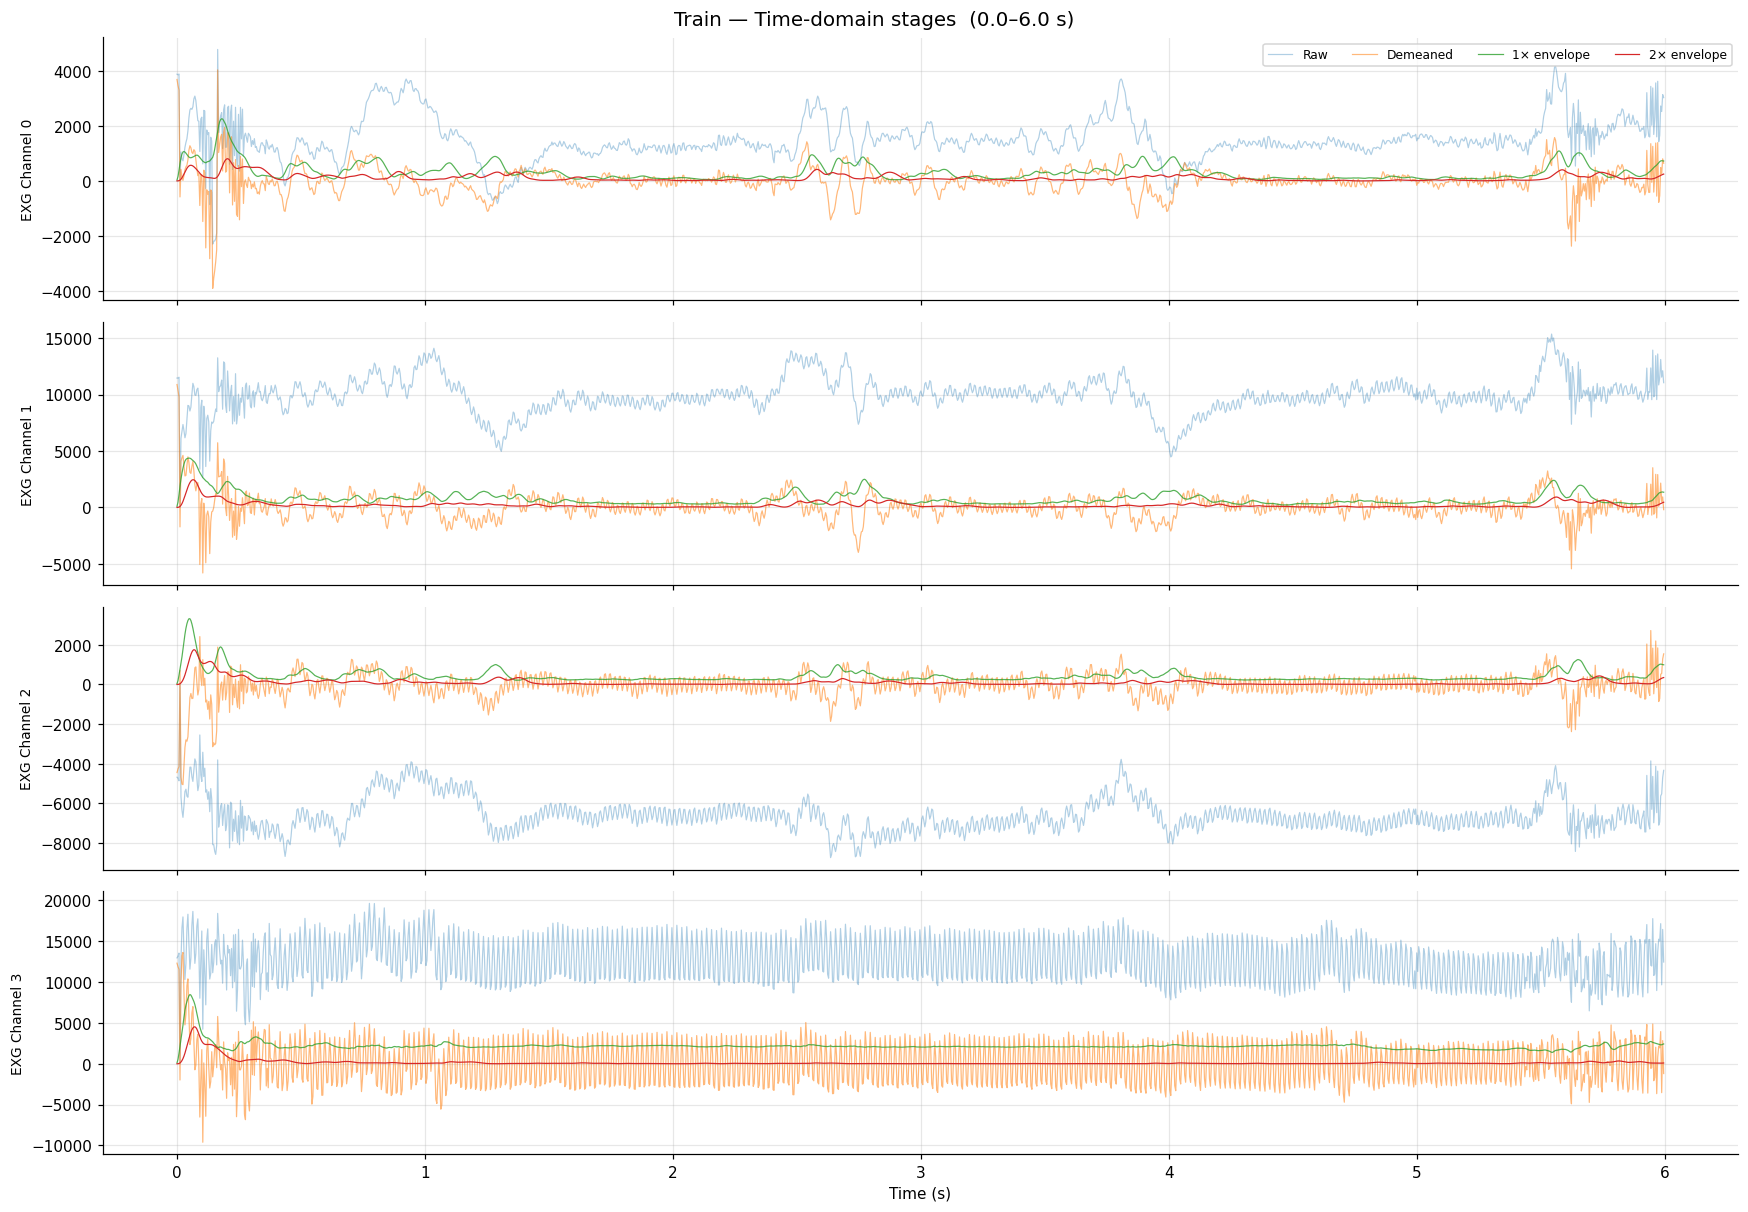

In [30]:
# ── configurable view window ─────────────────────────────────────────────────
VIEW_START_S = 0.0    # seconds
VIEW_END_S   = 6.0    # seconds  (set to None for full recording)

if VIEW_END_S is None:
    sl = slice(None)
else:
    i0 = int(VIEW_START_S * FS)
    i1 = int(VIEW_END_S   * FS)
    sl = slice(i0, i1)

t = time_s[sl]
stages = [
    (raw[sl],      'Raw',         0.35),
    (demeaned[sl], 'Demeaned',    0.55),
    (env1[sl],     '1× envelope', 0.80),
    (env2[sl],     '2× envelope', 1.00),
]

n_ch = len(EMG_CHANNELS)
fig, axes = plt.subplots(n_ch, 1, figsize=(16, 2.8 * n_ch), sharex=True)
fig.suptitle(f'{DATASET_LABEL} — Time-domain stages  ({VIEW_START_S}–{VIEW_END_S} s)', fontsize=13)

for ch, ax in enumerate(axes):
    for data, label, alpha in stages:
        ax.plot(t, data[:, ch], label=label, alpha=alpha, linewidth=0.8)
    ax.set_ylabel(EMG_CHANNELS[ch], fontsize=9)
    if ch == 0:
        ax.legend(loc='upper right', fontsize=8, ncol=4)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

## 4 · Finger extension angles over time

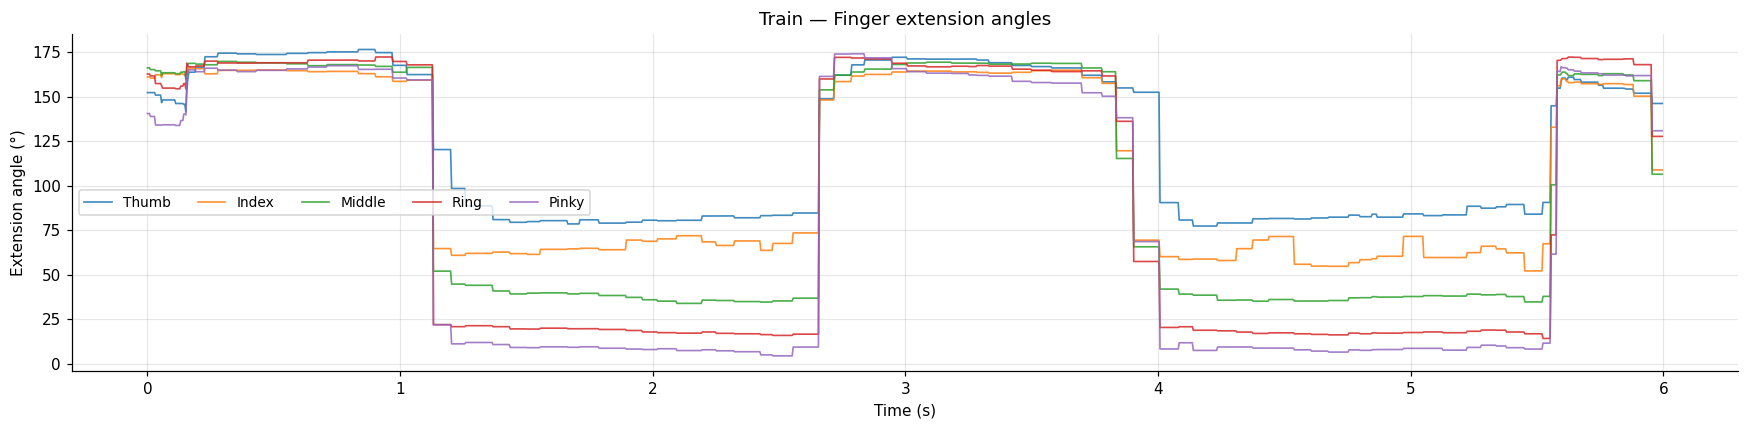

In [31]:
fig, ax = plt.subplots(figsize=(16, 4))
for i, (col, name) in enumerate(zip(ANGLE_COLS, FINGER_NAMES)):
    ax.plot(time_s[sl], angles[sl, i], label=name, color=FINGER_COLORS[i],
            linewidth=1.1, alpha=0.85)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Extension angle (°)')
ax.set_title(f'{DATASET_LABEL} — Finger extension angles')
ax.legend(ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

## 5 · EMG envelope + finger angles overlay

Shows the 2× preprocessed envelope of each EMG channel alongside all five finger angles on a twin axis. Use `CHANNEL` to select which channel to overlay.

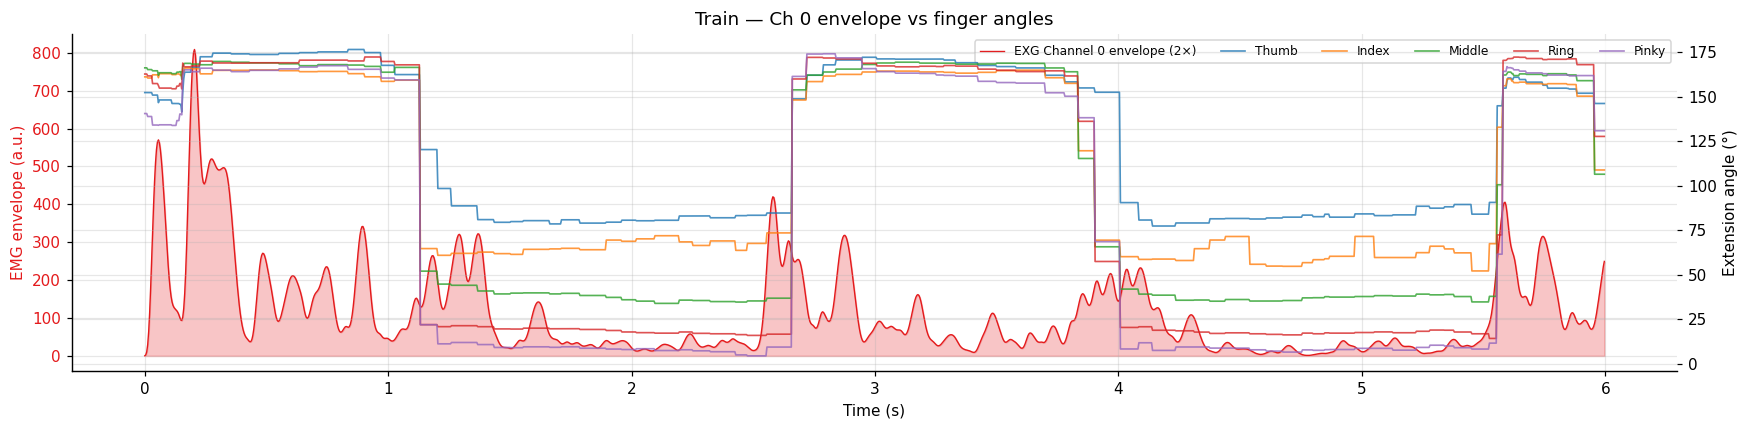

In [32]:
CHANNEL = 0   # ← 0–3

fig, ax1 = plt.subplots(figsize=(16, 4))
ax1.fill_between(t, env2[sl, CHANNEL], alpha=0.25, color=CH_COLORS[CHANNEL])
ax1.plot(t, env2[sl, CHANNEL], color=CH_COLORS[CHANNEL], linewidth=0.9,
         label=f'{EMG_CHANNELS[CHANNEL]} envelope (2×)')
ax1.set_ylabel('EMG envelope (a.u.)', color=CH_COLORS[CHANNEL])
ax1.tick_params(axis='y', labelcolor=CH_COLORS[CHANNEL])

ax2 = ax1.twinx()
for i, (name, c) in enumerate(zip(FINGER_NAMES, FINGER_COLORS)):
    ax2.plot(t, angles[sl, i], label=name, color=c, linewidth=1.1, alpha=0.8)
ax2.set_ylabel('Extension angle (°)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=8, ncol=6, loc='upper right')
ax1.set_xlabel('Time (s)')
ax1.set_title(f'{DATASET_LABEL} — Ch {CHANNEL} envelope vs finger angles')
plt.tight_layout()
plt.show()

## 6 · Frequency-domain analysis

### 6a · FFT magnitude spectrum (linear + log scale)

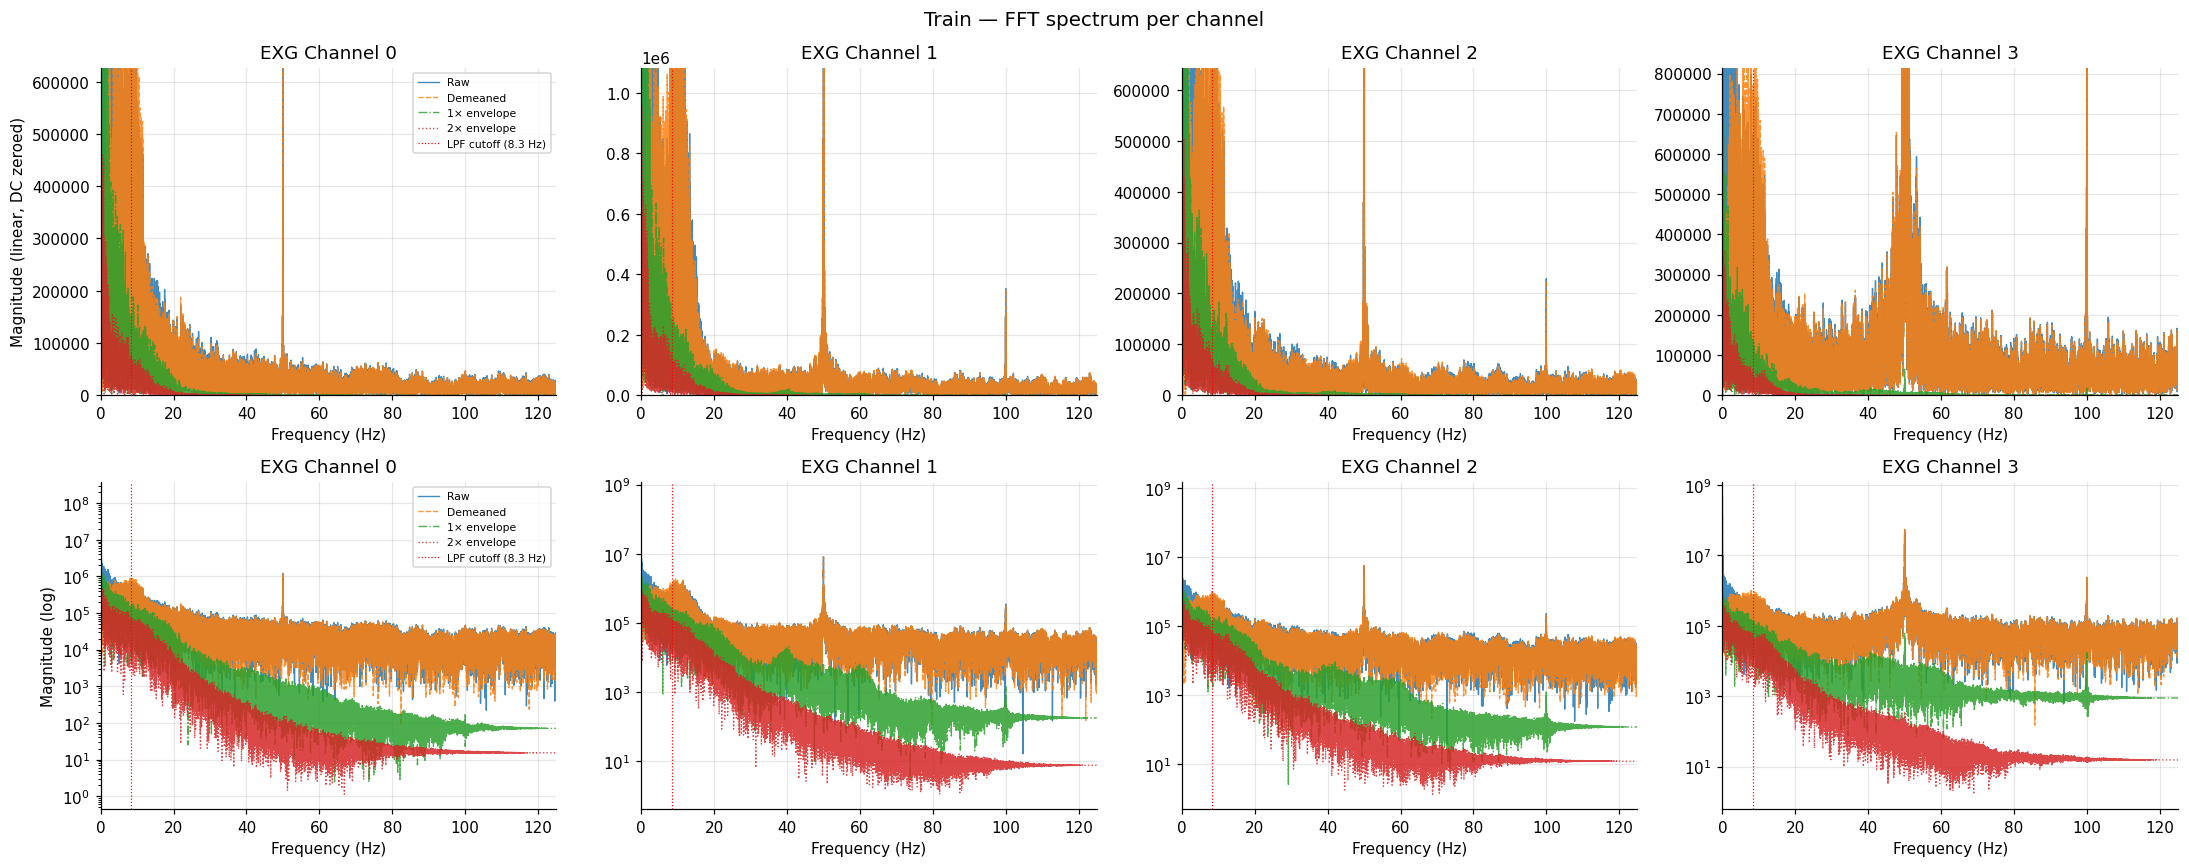

In [33]:
# Use full recording for frequency analysis
# DC bin (f=0) is zeroed before the linear plot — the DC term equals the
# signal mean summed over all samples and completely dwarfs the rest.
fig, axes = plt.subplots(2, n_ch, figsize=(5 * n_ch, 8))
fig.suptitle(f'{DATASET_LABEL} — FFT spectrum per channel', fontsize=13)

for ch in range(n_ch):
    lin_peaks = []  # collect non-DC magnitudes to set a sensible ylim
    for data, label, ls in [
        (raw[:, ch],      'Raw',         '-'),
        (demeaned[:, ch], 'Demeaned',    '--'),
        (env1[:, ch],     '1× envelope', '-.'),
        (env2[:, ch],     '2× envelope', ':'),
    ]:
        freqs   = np.fft.rfftfreq(len(data), d=1 / FS)
        mag     = np.abs(np.fft.rfft(data))
        mag_lin = mag.copy()
        mag_lin[0] = 0          # zero DC so linear scale shows the actual spectrum
        lin_peaks.append(mag_lin[1:])
        axes[0, ch].plot(freqs, mag_lin, label=label, ls=ls, linewidth=0.9, alpha=0.85)
        axes[1, ch].semilogy(freqs, mag + 1, label=label, ls=ls, linewidth=0.9, alpha=0.85)

    # cap linear y-axis at 99th percentile so low-energy detail is visible
    p99 = np.percentile(np.concatenate(lin_peaks), 99)
    axes[0, ch].set_ylim(0, p99 * 1.35)

    for row in range(2):
        axes[row, ch].set_xlim(0, FS / 2)
        axes[row, ch].set_xlabel('Frequency (Hz)')
        axes[row, ch].set_title(EMG_CHANNELS[ch])
        axes[row, ch].axvline(8.3, color='red', linewidth=0.8, linestyle=':', label='LPF cutoff (8.3 Hz)')
        if ch == 0:
            axes[row, ch].legend(fontsize=7)

axes[0, 0].set_ylabel('Magnitude (linear, DC zeroed)')
axes[1, 0].set_ylabel('Magnitude (log)')
plt.tight_layout()
plt.show()

### 6b · Welch power spectral density

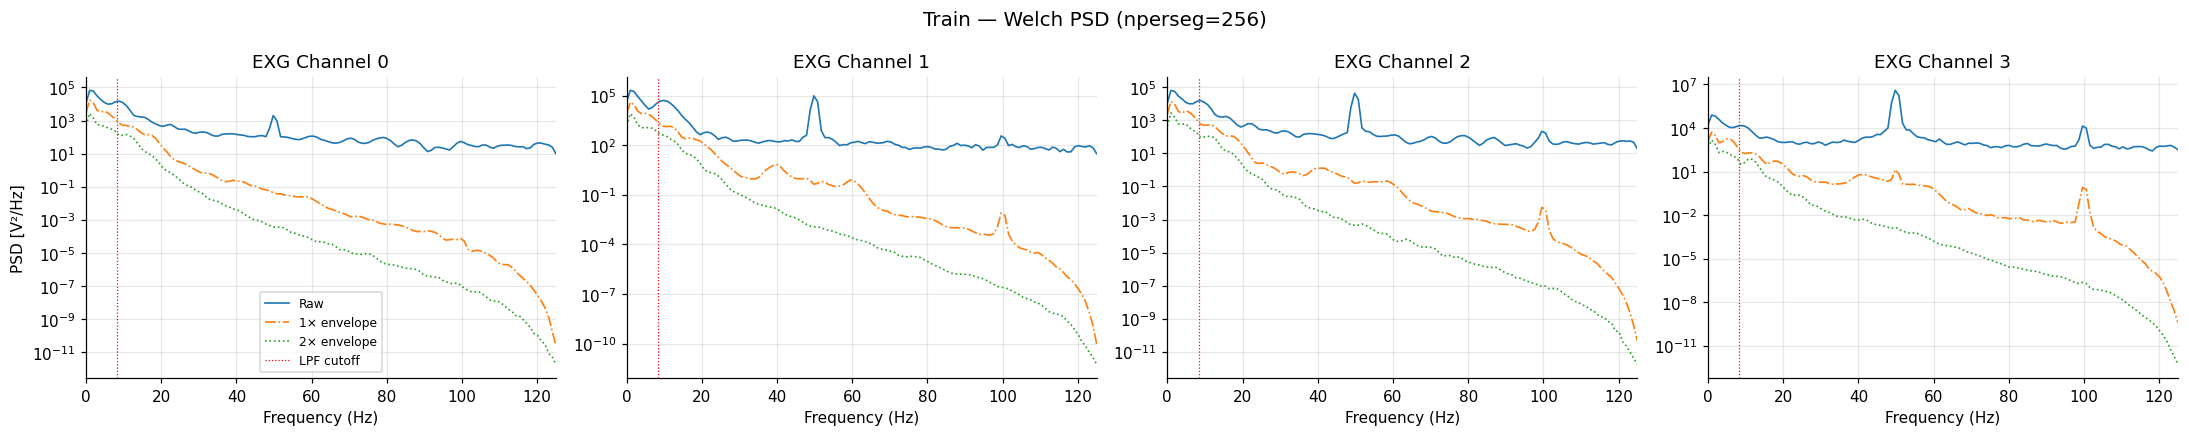

In [34]:
NPERSEG = 256   # Welch segment length

fig, axes = plt.subplots(1, n_ch, figsize=(5 * n_ch, 4), sharey=False)
fig.suptitle(f'{DATASET_LABEL} — Welch PSD (nperseg={NPERSEG})', fontsize=13)

for ch in range(n_ch):
    for data, label, ls in [
        (raw[:, ch],  'Raw',         '-'),
        (env1[:, ch], '1× envelope', '-.'),
        (env2[:, ch], '2× envelope', ':'),
    ]:
        f, pxx = welch(data, fs=FS, nperseg=NPERSEG)
        axes[ch].semilogy(f, pxx, label=label, ls=ls, linewidth=1.1)

    axes[ch].axvline(8.3, color='red', linewidth=0.8, linestyle=':', label='LPF cutoff')
    axes[ch].set_xlabel('Frequency (Hz)')
    axes[ch].set_title(EMG_CHANNELS[ch])
    axes[ch].set_xlim(0, FS / 2)
    if ch == 0:
        axes[ch].set_ylabel('PSD [V²/Hz]')
        axes[ch].legend(fontsize=8)

plt.tight_layout()
plt.show()

### 6c · Short-time spectrogram (raw signal)

Reveals how energy is distributed across frequencies over time — useful to spot movement bursts, noise artifacts, and the dominant muscle bands.

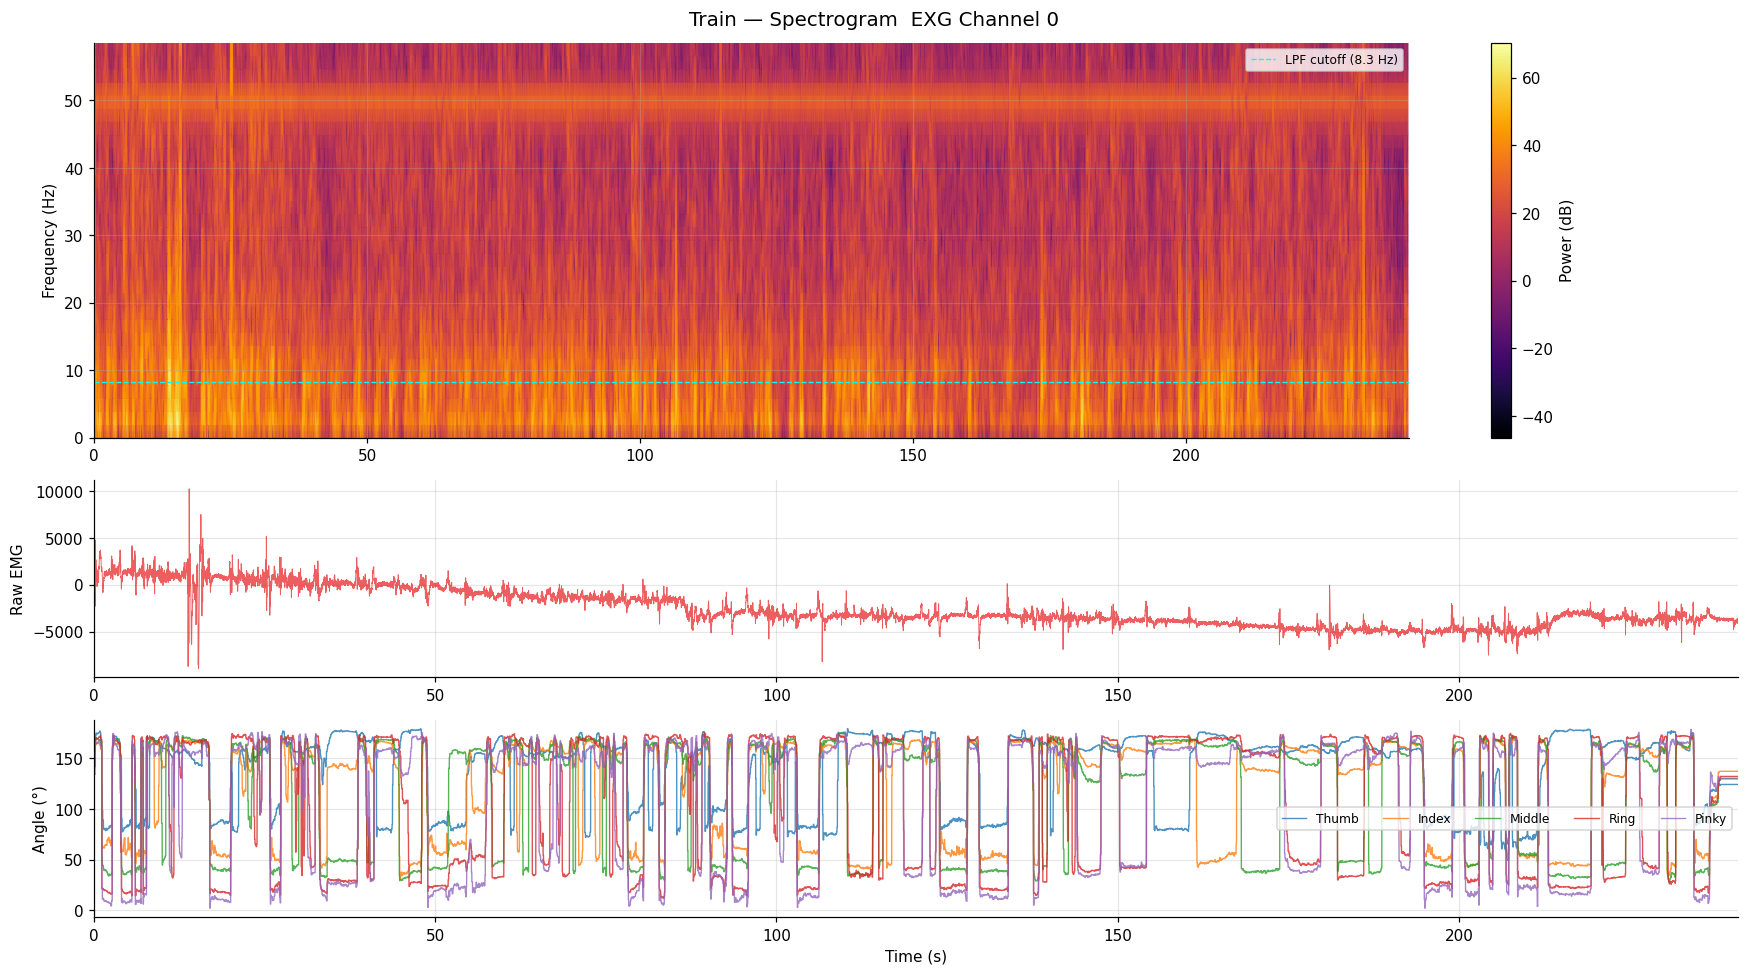

In [35]:
SPEC_CHANNEL = 0   # ← which channel to spectogram
NPERSEG_SPEC = 128
NOVERLAP     = 112
FMAX_DISPLAY = 60  # Hz — crop display above this

f, t_spec, Sxx = spectrogram(
    raw[:, SPEC_CHANNEL], fs=FS,
    nperseg=NPERSEG_SPEC, noverlap=NOVERLAP,
    scaling='density'
)
fmask = f <= FMAX_DISPLAY

fig, axes = plt.subplots(3, 1, figsize=(16, 9), gridspec_kw={'height_ratios': [2, 1, 1]})
fig.suptitle(f'{DATASET_LABEL} — Spectrogram  {EMG_CHANNELS[SPEC_CHANNEL]}', fontsize=13)

# spectrogram
im = axes[0].pcolormesh(
    t_spec, f[fmask], 10 * np.log10(Sxx[fmask] + 1e-12),
    shading='gouraud', cmap='inferno'
)
axes[0].set_ylabel('Frequency (Hz)')
axes[0].axhline(8.3, color='cyan', linewidth=0.9, linestyle='--', label='LPF cutoff (8.3 Hz)')
axes[0].legend(fontsize=8, loc='upper right')
plt.colorbar(im, ax=axes[0], label='Power (dB)')

# raw signal
axes[1].plot(time_s, raw[:, SPEC_CHANNEL], linewidth=0.6, color=CH_COLORS[SPEC_CHANNEL], alpha=0.7)
axes[1].set_ylabel('Raw EMG')

# finger angles
for i, (name, c) in enumerate(zip(FINGER_NAMES, FINGER_COLORS)):
    axes[2].plot(time_s, angles[:, i], label=name, color=c, linewidth=0.9, alpha=0.8)
axes[2].set_ylabel('Angle (°)')
axes[2].set_xlabel('Time (s)')
axes[2].legend(ncol=5, fontsize=8)

for ax in axes:
    ax.set_xlim(time_s[0], time_s[-1])

plt.tight_layout()
plt.show()

## 7 · Feature landscape over time

All six hand-crafted features (MAV, RMS, WL, std, ZCR, SSC) computed with a rolling window, plotted per channel. ZCR and SSC are computed on the **demeaned** (bipolar) signal; the others on the **envelope**.

In [36]:
print('Computing windowed features (window=%d samples = %.0f ms)…' % (WINDOW_SIZE, WINDOW_SIZE / FS * 1000))

F_MAV = feat_mav(env1)
F_RMS = feat_rms(env1)
F_WL  = feat_wl(env1)
F_STD = feat_std(env1)
F_ZCR = feat_zcr(demeaned)
F_SSC = feat_ssc(demeaned)

FEATURES = [
    (F_MAV, 'MAV  (mean abs value)',  '#1b9e77', 'envelope power — closely tracks activation level'),
    (F_RMS, 'RMS  (root mean square)', '#d95f02', 'similar to MAV but weights large spikes more'),
    (F_WL,  'WL   (waveform length)',  '#7570b3', 'signal complexity / contraction velocity'),
    (F_STD, 'Std  (standard dev)',     '#e7298a', 'spread around envelope mean'),
    (F_ZCR, 'ZCR  (zero-crossing rate)','#66a61e','frequency proxy — high during fast oscillations'),
    (F_SSC, 'SSC  (slope sign change)', '#e6ab02','local frequency — counts direction reversals'),
]

print('Done.')

Computing windowed features (window=50 samples = 200 ms)…
Done.


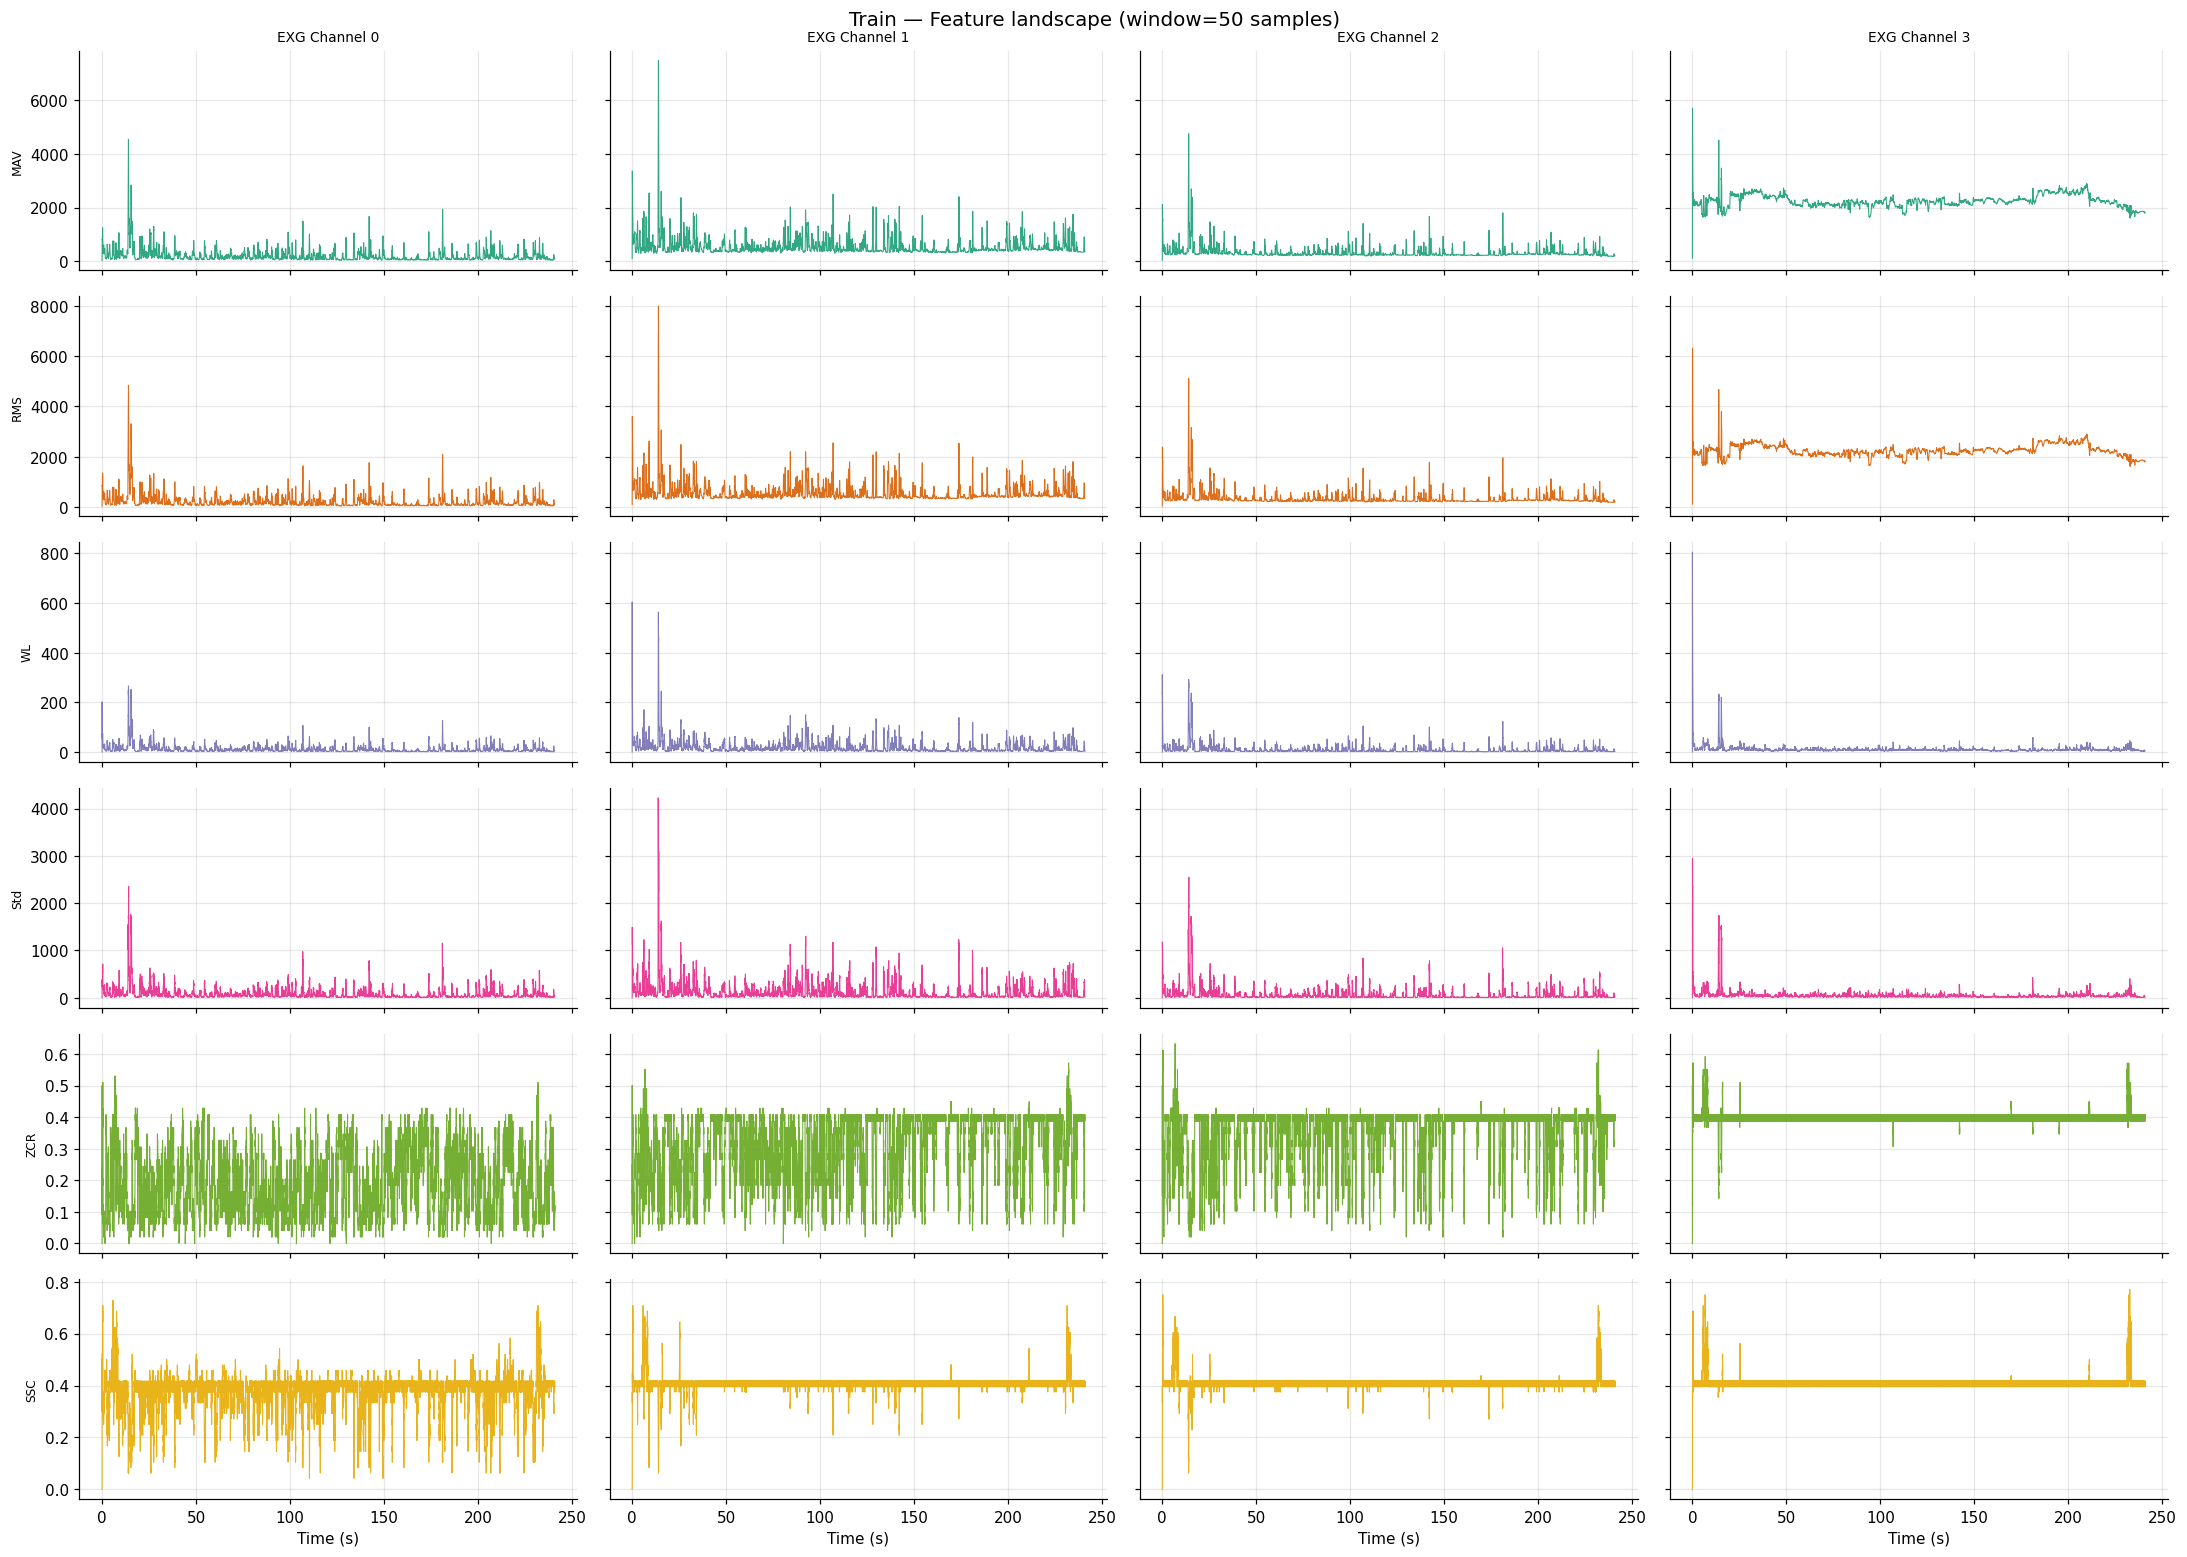

Feature guide:
  MAV  (mean abs value)                   envelope power — closely tracks activation level
  RMS  (root mean square)                 similar to MAV but weights large spikes more
  WL   (waveform length)                  signal complexity / contraction velocity
  Std  (standard dev)                     spread around envelope mean
  ZCR  (zero-crossing rate)               frequency proxy — high during fast oscillations
  SSC  (slope sign change)                local frequency — counts direction reversals


In [37]:
# One row per feature, one subplot per channel  —  full recording
n_feat = len(FEATURES)
fig, axes = plt.subplots(n_feat, n_ch, figsize=(5 * n_ch, 2.4 * n_feat), sharey='row', sharex=True)
fig.suptitle(f'{DATASET_LABEL} — Feature landscape (window={WINDOW_SIZE} samples)', fontsize=13)

for fi, (fdata, fname, fcolor, fdesc) in enumerate(FEATURES):
    for ch in range(n_ch):
        ax = axes[fi, ch]
        ax.plot(time_s, fdata[:, ch], color=fcolor, linewidth=0.7, alpha=0.9)
        if ch == 0:
            ax.set_ylabel(fname.split('(')[0].strip(), fontsize=8)
        if fi == 0:
            ax.set_title(EMG_CHANNELS[ch], fontsize=9)
        if fi == n_feat - 1:
            ax.set_xlabel('Time (s)')

plt.tight_layout()
plt.show()

# Print feature descriptions
print('Feature guide:')
for _, fname, _, fdesc in FEATURES:
    print(f'  {fname:<38}  {fdesc}')

## 8 · Pairwise channel ratios

Six ratios from the four channels. These are the inter-muscle balance features that let the model distinguish fingers that activate overlapping muscle groups.

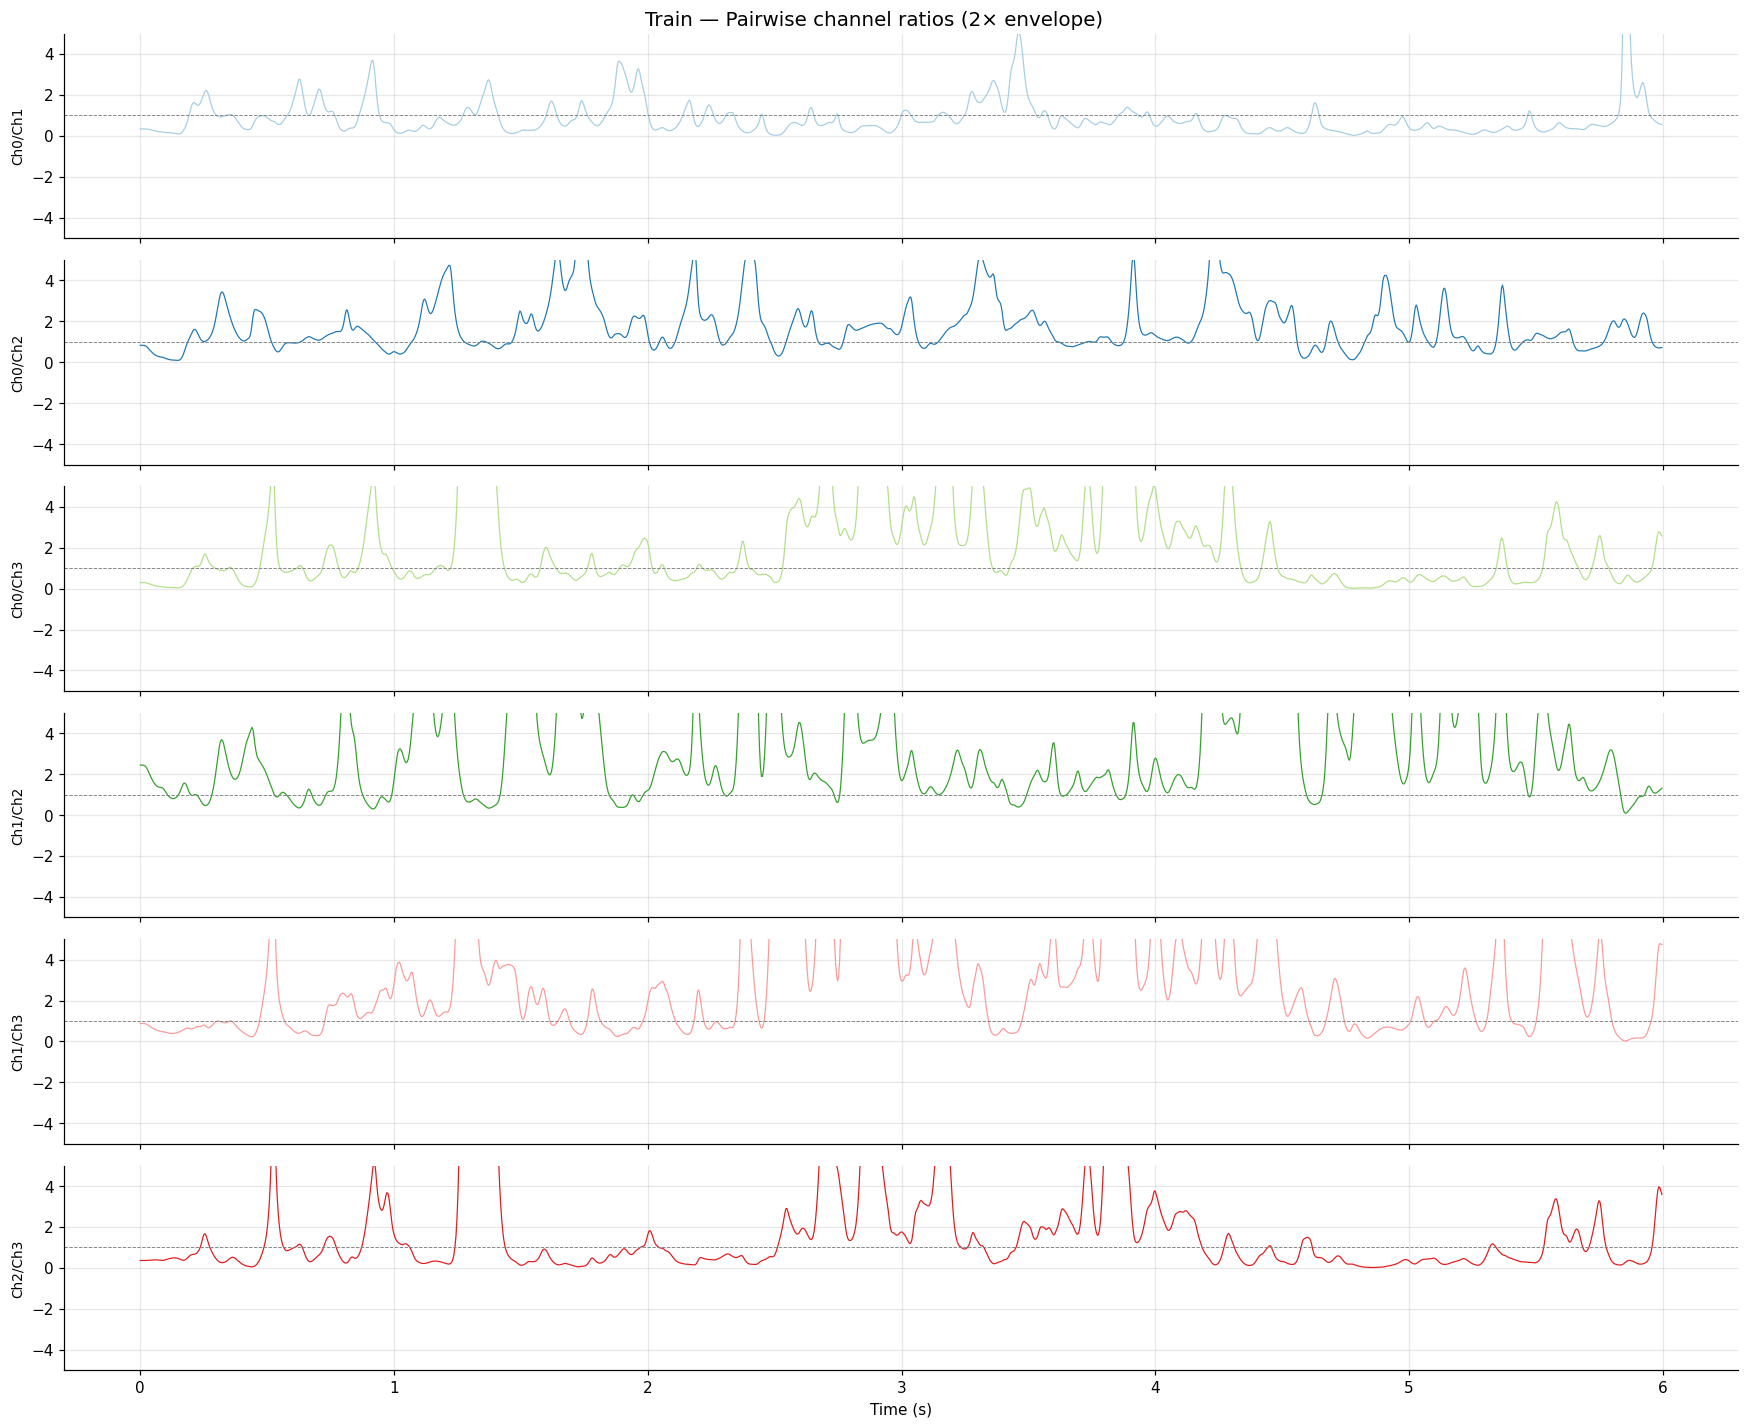

In [38]:
ratios, pairs = feat_pairwise_ratios(env2)
ratio_labels  = [f'Ch{i}/Ch{j}' for i, j in pairs]
RATIO_COLORS  = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']

fig, axes = plt.subplots(len(pairs), 1, figsize=(16, 2.2 * len(pairs)), sharex=True)
fig.suptitle(f'{DATASET_LABEL} — Pairwise channel ratios (2× envelope)', fontsize=13)

for k, ax in enumerate(axes):
    ax.plot(time_s[sl], ratios[sl, k], color=RATIO_COLORS[k], linewidth=0.8)
    ax.axhline(1.0, color='gray', linewidth=0.6, linestyle='--')
    ax.set_ylabel(ratio_labels[k], fontsize=9)
    ax.set_ylim(-5, 5)

axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

## 9 · Feature–angle correlation heatmap

Pearson correlation between every feature × channel combination and each finger angle. High absolute correlation (dark cells) indicates a feature that carries discriminative information for that finger.

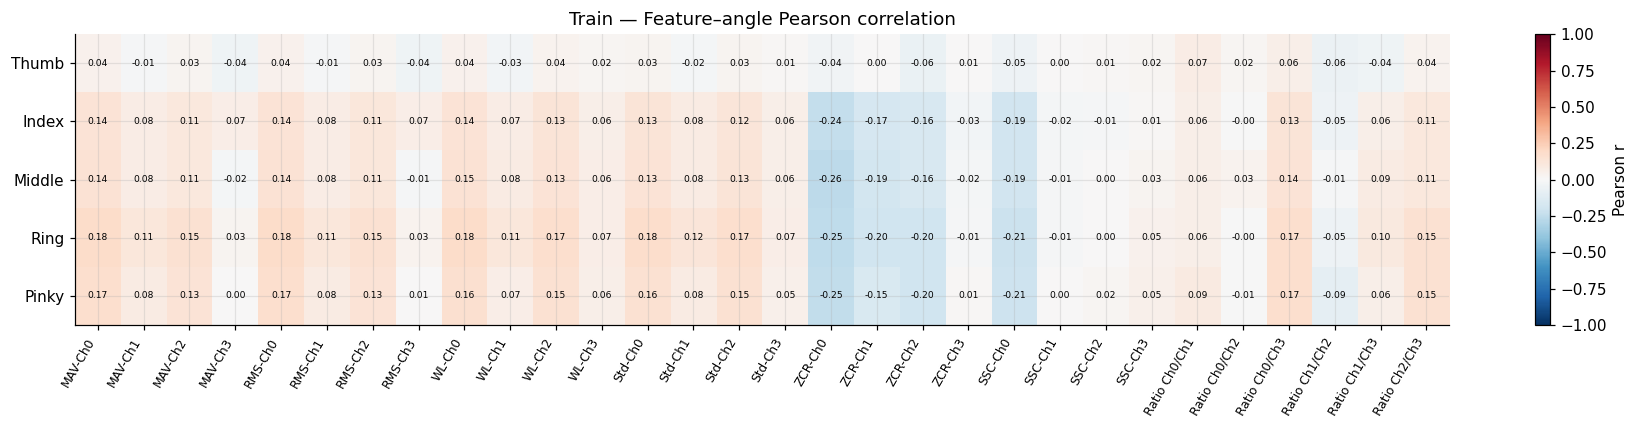

In [39]:
# Build feature matrix with descriptive column names
feat_blocks = []
feat_col_names = []

for fdata, fname, _, _ in FEATURES:
    short = fname.split('(')[0].strip()          # e.g. 'MAV'
    for ch in range(n_ch):
        feat_blocks.append(fdata[:, ch])
        feat_col_names.append(f'{short}-Ch{ch}')

for k, label in enumerate(ratio_labels):
    feat_blocks.append(ratios[:, k])
    feat_col_names.append(f'Ratio {label}')

feat_matrix = np.column_stack(feat_blocks)       # (N, n_features)

# Pearson correlation
corr_rows = []
for ai in range(len(ANGLE_COLS)):
    row = []
    a_col = angles[:, ai]
    for fi in range(feat_matrix.shape[1]):
        c = np.corrcoef(feat_matrix[:, fi], a_col)[0, 1]
        row.append(0.0 if np.isnan(c) else c)
    corr_rows.append(row)

corr = np.array(corr_rows)   # (n_angles, n_features)

fig, ax = plt.subplots(figsize=(max(14, len(feat_col_names) * 0.55), 4))
im = ax.imshow(corr, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label='Pearson r')

ax.set_xticks(range(len(feat_col_names)))
ax.set_xticklabels(feat_col_names, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(FINGER_NAMES)))
ax.set_yticklabels(FINGER_NAMES)
ax.set_title(f'{DATASET_LABEL} — Feature–angle Pearson correlation')

# annotate values
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        v = corr[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                fontsize=6, color='white' if abs(v) > 0.5 else 'black')

plt.tight_layout()
plt.show()

## 9b · How to read correlation values & other feature-selection methods

### Pearson r — the linear correlation coefficient

$$r = \frac{\sum(x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum(x_i-\bar x)^2 \cdot \sum(y_i-\bar y)^2}} \in [-1,\, 1]$$

| |r| range | Interpretation for this study |
|------------|--------------------------------|
| 0.00–0.10 | Negligible — feature carries almost no linear signal for that finger |
| 0.10–0.30 | Weak — may help in combination, not alone |
| 0.30–0.50 | Moderate — worth including; test its contribution in ablation |
| 0.50–0.70 | Strong — reliable discriminator for that angle |
| 0.70–1.00 | Very strong — dominant predictor; watch for overfitting if > 0.90 |

**Sign**: positive r means feature rises as the finger extends; negative means the opposite muscle group is dominant.

**Limitation**: Pearson only captures *linear* monotonic relationships. A feature can be highly informative but show r ≈ 0 if the relationship is U-shaped or threshold-gated (common in EMG).

---

### Other methods and when to prefer them

| Method | Captures | Use when |
|--------|----------|----------|
| **Spearman ρ** | Monotonic (non-linear) rank correlation | EMG envelope is often non-linearly saturated; Spearman survives outliers better |
| **Mutual Information (MI)** | Any statistical dependency, incl. non-monotonic | Best overall sensitivity; use `sklearn.feature_selection.mutual_info_regression` |
| **Point-biserial r** | Correlation with a binary target | If you binarise angles into flexed/extended states |
| **ANOVA F-score** | Between-class variance / within-class variance | Works well with discretised finger states |
| **Variance threshold** | Raw feature spread | Remove near-zero-variance features first (dead channels, sensor saturation) |
| **VIF** | Multicollinearity between features | Before fitting a linear model — VIF > 5 means two features say the same thing |

**Recommended workflow for this dataset:**
1. Remove variance-threshold failures (dead channels).
2. Pearson heatmap (section 9) — fast first pass.
3. Spearman ρ + MI (section 9b code cell) — non-linear cross-check.
4. Feature-feature collinearity map (section 9c) — prune redundant pairs.
5. Ablation: train model with all features, then without low-MI ones, compare.

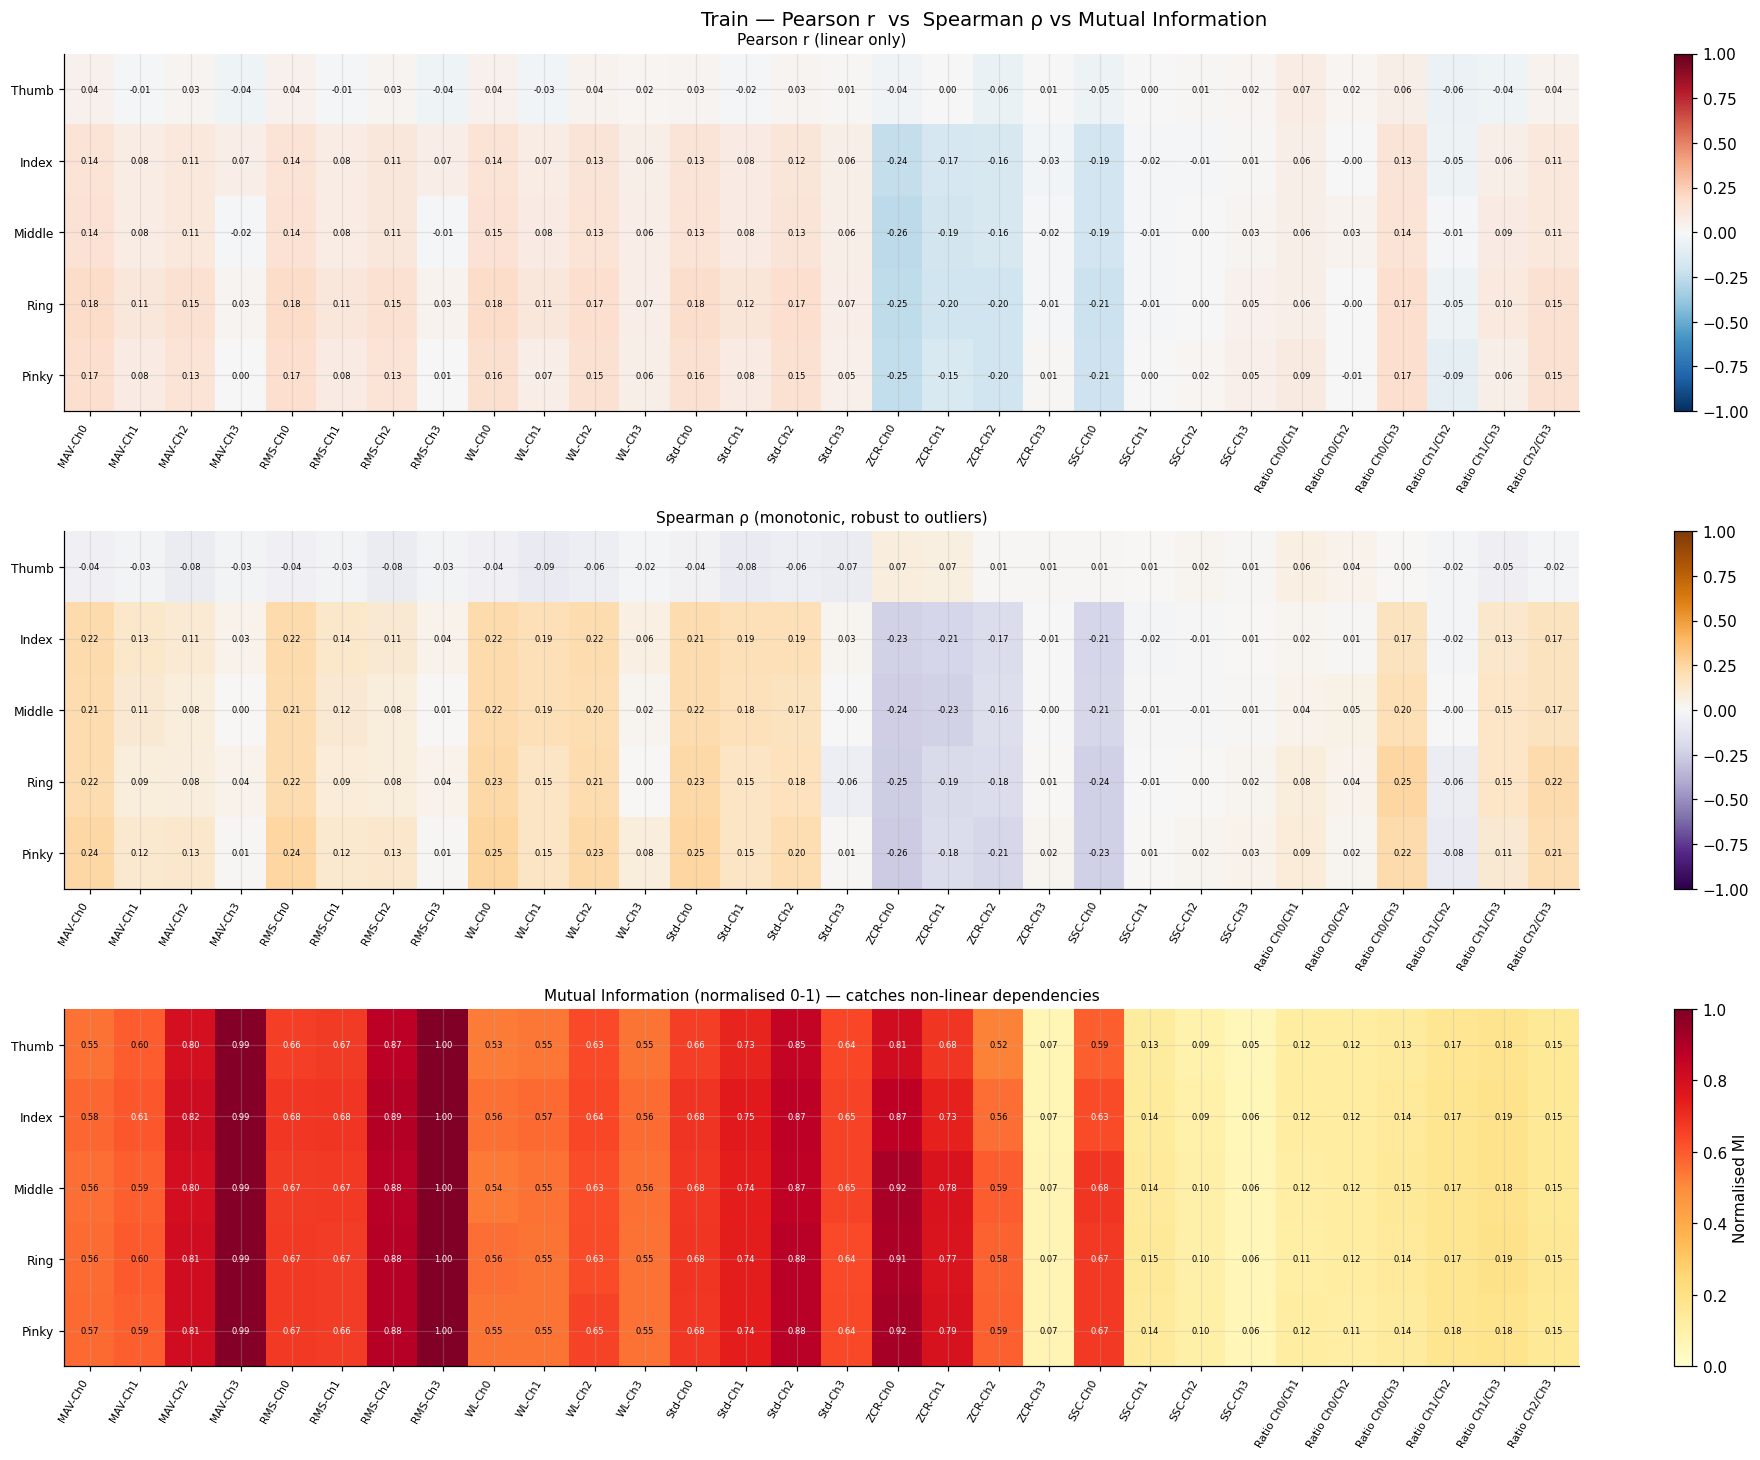

In [40]:
from scipy.stats import spearmanr

try:
    from sklearn.feature_selection import mutual_info_regression
    HAS_SKLEARN = True
except ImportError:
    HAS_SKLEARN = False
    print('scikit-learn not found — Mutual Information plot skipped.')

# ── Spearman ρ ────────────────────────────────────────────────────────────
spear_rows = []
for ai in range(len(ANGLE_COLS)):
    row = []
    for fi in range(feat_matrix.shape[1]):
        rho, _ = spearmanr(feat_matrix[:, fi], angles[:, ai])
        row.append(0.0 if np.isnan(rho) else rho)
    spear_rows.append(row)
spear = np.array(spear_rows)

n_plots = 3 if HAS_SKLEARN else 2
fig, axes = plt.subplots(n_plots, 1,
    figsize=(max(14, len(feat_col_names) * 0.6), 4.5 * n_plots))
fig.suptitle(
    f'{DATASET_LABEL} — Pearson r  vs  Spearman ρ'
    + (' vs Mutual Information' if HAS_SKLEARN else ''), fontsize=13)

for ax, data, title, cmap in zip(
    axes[:2],
    [corr, spear],
    ['Pearson r (linear only)', 'Spearman ρ (monotonic, robust to outliers)'],
    ['RdBu_r', 'PuOr_r'],
):
    im = ax.imshow(data, aspect='auto', cmap=cmap, vmin=-1, vmax=1)
    plt.colorbar(im, ax=ax)
    ax.set_xticks(range(len(feat_col_names)))
    ax.set_xticklabels(feat_col_names, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(FINGER_NAMES)))
    ax.set_yticklabels(FINGER_NAMES, fontsize=8)
    ax.set_title(title, fontsize=10)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    fontsize=5.5, color='white' if abs(v) > 0.5 else 'black')

if HAS_SKLEARN:
    mi_rows = []
    for ai in range(len(ANGLE_COLS)):
        mi = mutual_info_regression(feat_matrix, angles[:, ai], random_state=0)
        mi_rows.append(mi / (mi.max() + 1e-8))
    mi_arr = np.array(mi_rows)

    ax = axes[2]
    im = ax.imshow(mi_arr, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, label='Normalised MI')
    ax.set_xticks(range(len(feat_col_names)))
    ax.set_xticklabels(feat_col_names, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(FINGER_NAMES)))
    ax.set_yticklabels(FINGER_NAMES, fontsize=8)
    ax.set_title(
        'Mutual Information (normalised 0-1) — catches non-linear dependencies',
        fontsize=10)
    for i in range(mi_arr.shape[0]):
        for j in range(mi_arr.shape[1]):
            v = mi_arr[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    fontsize=5.5, color='white' if v > 0.6 else 'black')

plt.tight_layout()
plt.show()

## 9c · Feature–feature collinearity map

A Pearson correlation matrix across **all features and all finger angles together**.

- **Bright red/blue off-diagonal blocks between two features** = they are redundant; keeping both does not add new information and inflates model variance.
- **Bright blocks in the gold-bordered zone** = a feature strongly predicts an angle (same information as section 9, shown here for context).
- **Near-zero blocks between two features** = complementary; both should be kept.

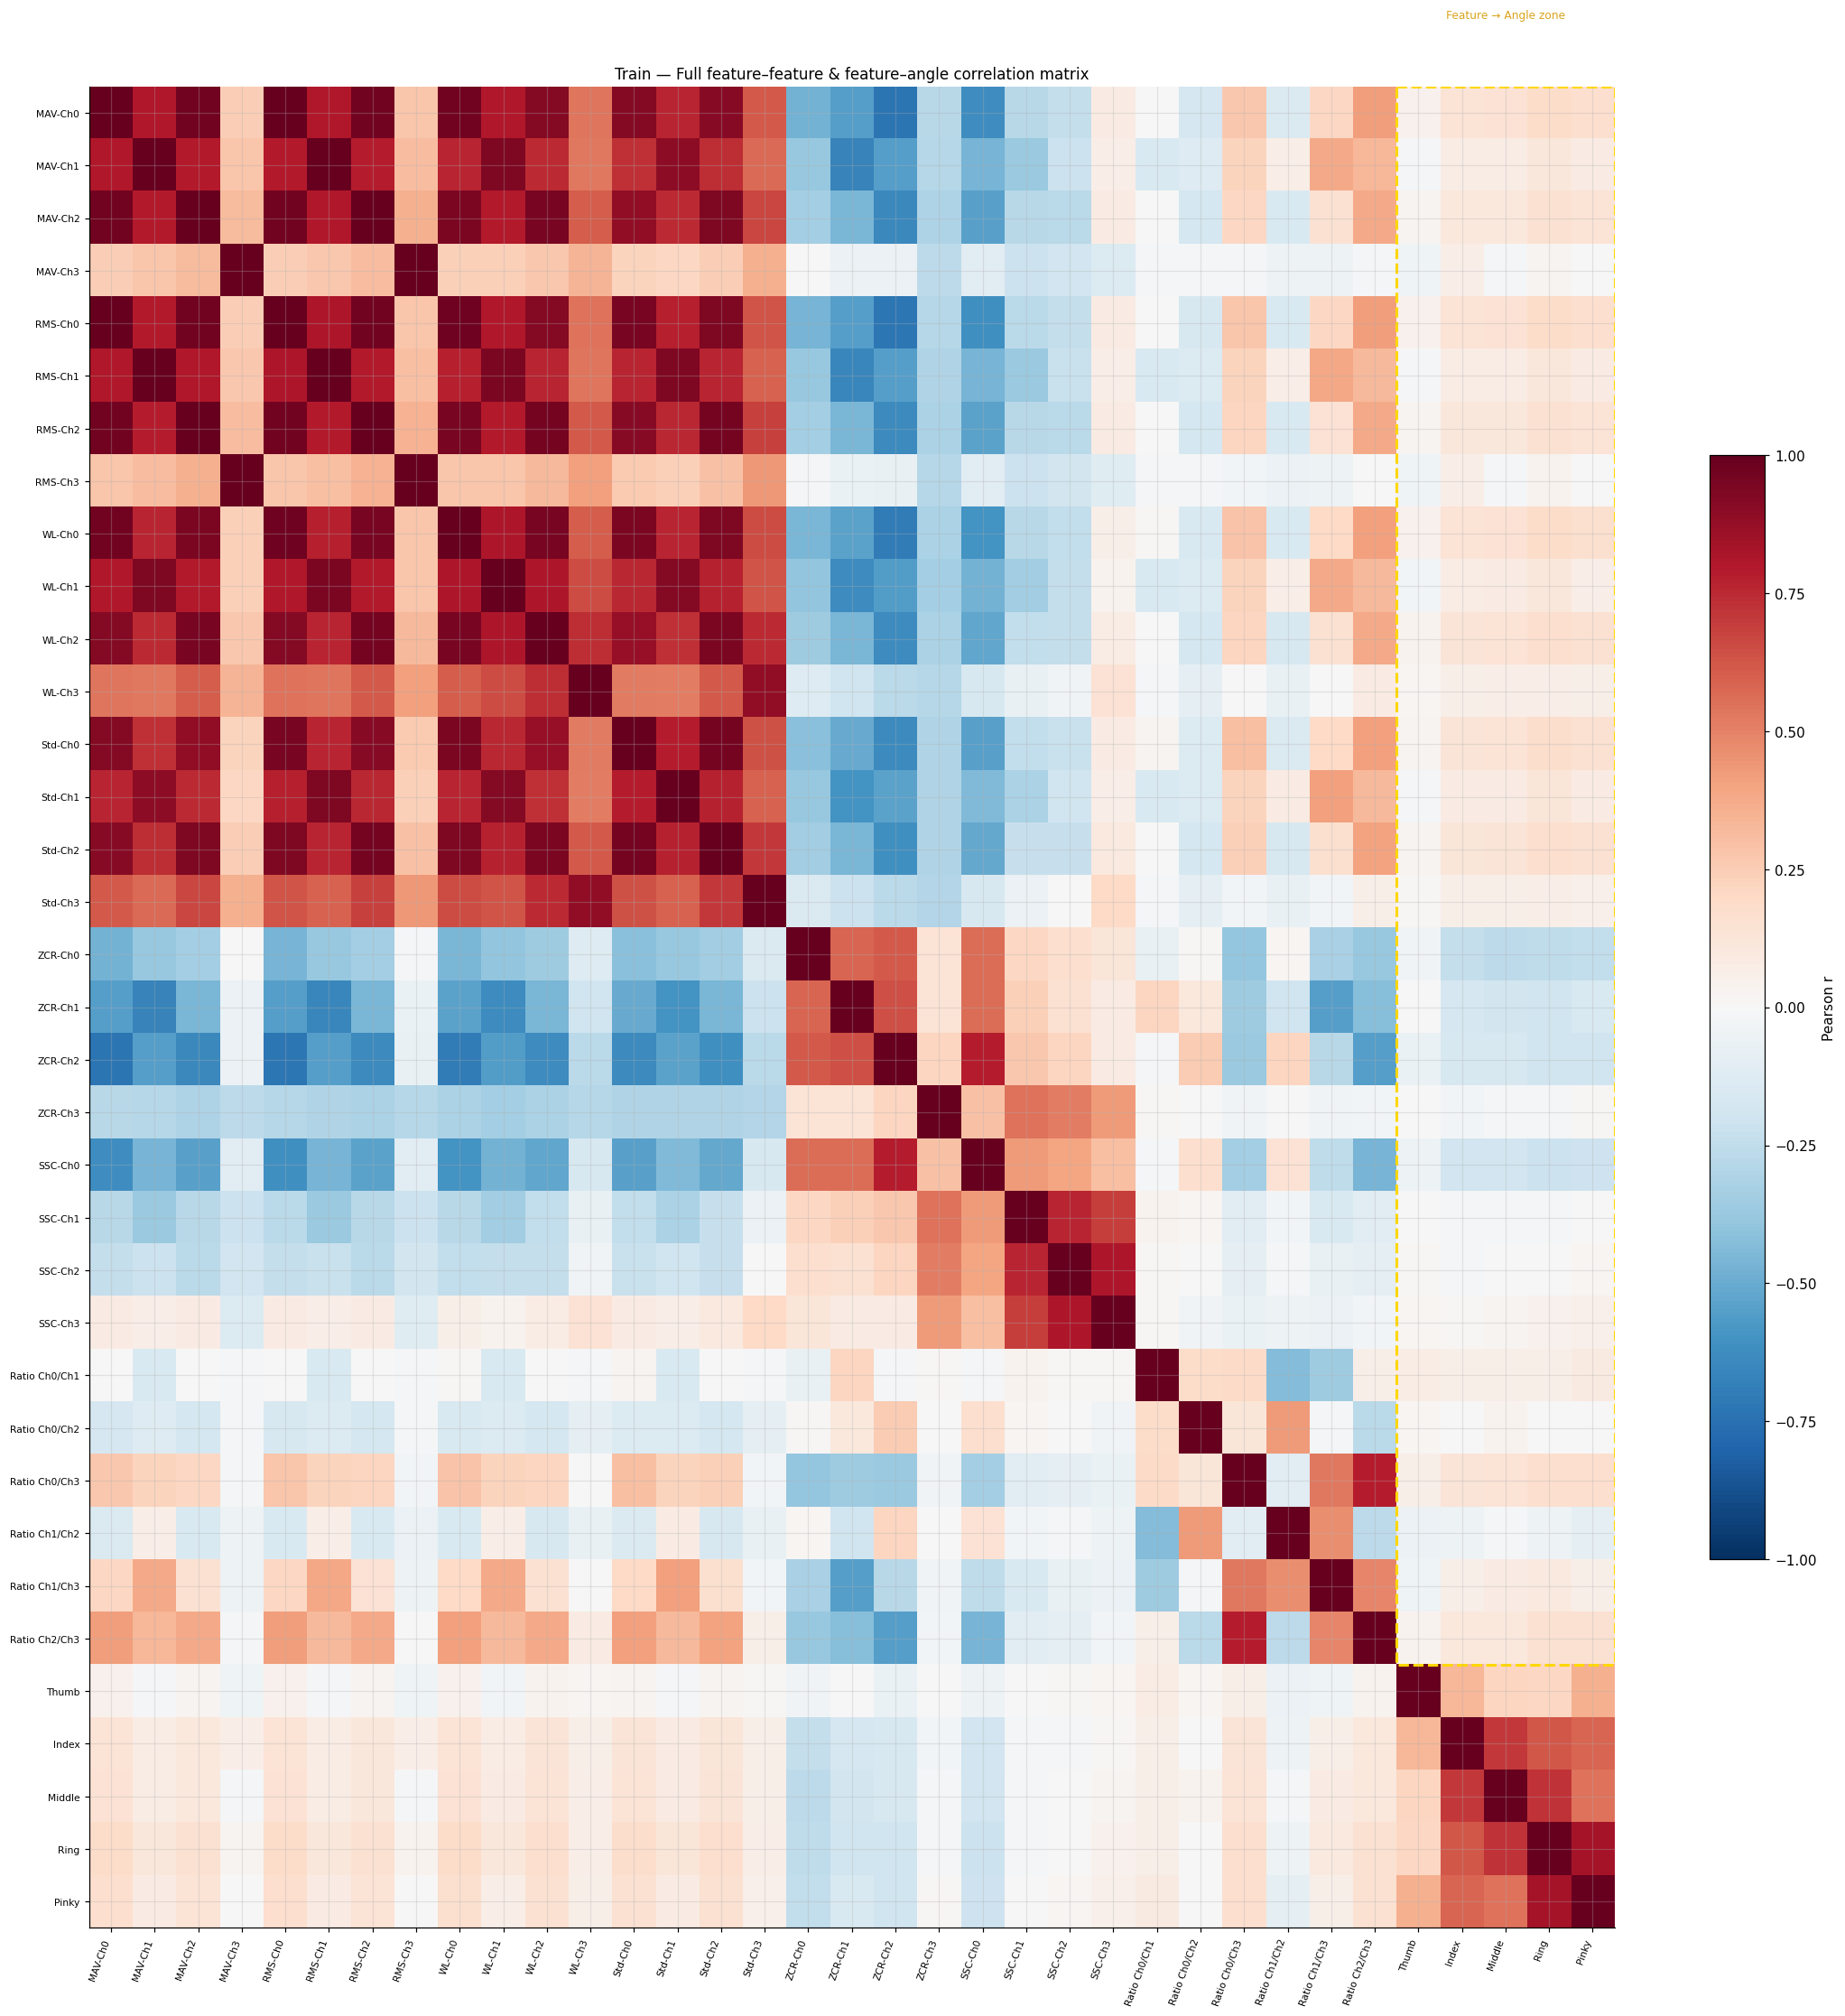

Top 10 most collinear feature pairs (candidates for pruning):
  MAV-Ch2                ↔ RMS-Ch2                 r=+0.997  ← consider dropping one
  MAV-Ch0                ↔ RMS-Ch0                 r=+0.996  ← consider dropping one
  MAV-Ch3                ↔ RMS-Ch3                 r=+0.996  ← consider dropping one
  MAV-Ch1                ↔ RMS-Ch1                 r=+0.994  ← consider dropping one
  RMS-Ch0                ↔ WL-Ch0                  r=+0.971  ← consider dropping one
  MAV-Ch0                ↔ MAV-Ch2                 r=+0.968  ← consider dropping one
  RMS-Ch0                ↔ RMS-Ch2                 r=+0.966  ← consider dropping one
  MAV-Ch0                ↔ RMS-Ch2                 r=+0.964  ← consider dropping one
  MAV-Ch2                ↔ RMS-Ch0                 r=+0.964  ← consider dropping one
  MAV-Ch0                ↔ WL-Ch0                  r=+0.963  ← consider dropping one


In [41]:
# Full correlation matrix: all features + all finger angles
all_cols  = feat_col_names + FINGER_NAMES
all_data  = np.column_stack([feat_matrix, angles])

full_corr = np.corrcoef(all_data.T)
full_corr = np.nan_to_num(full_corr, nan=0.0)

n_all = len(all_cols)
fig, ax = plt.subplots(figsize=(max(14, n_all * 0.58), max(12, n_all * 0.58)))
im = ax.imshow(full_corr, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, shrink=0.6, label='Pearson r')

ax.set_xticks(range(n_all))
ax.set_xticklabels(all_cols, rotation=70, ha='right', fontsize=7)
ax.set_yticks(range(n_all))
ax.set_yticklabels(all_cols, fontsize=7)

# gold border around the feature→angle quadrant
n_f = len(feat_col_names)
n_a = len(FINGER_NAMES)
rect = plt.Rectangle((n_f - 0.5, -0.5), n_a, n_f,
    fill=False, edgecolor='gold', linewidth=2, linestyle='--')
ax.add_patch(rect)
ax.text(n_f + n_a / 2 - 0.5, -1.8, 'Feature → Angle zone',
        ha='center', fontsize=8, color='goldenrod')

ax.set_title(
    f'{DATASET_LABEL} — Full feature–feature & feature–angle correlation matrix',
    fontsize=11)
plt.tight_layout()
plt.show()

# ── Top collinear feature pairs ────────────────────────────────────────────
feat_feat_corr = full_corr[:n_f, :n_f]
pairs_list = []
for i in range(n_f):
    for j in range(i + 1, n_f):
        pairs_list.append(
            (abs(feat_feat_corr[i, j]),
             feat_col_names[i], feat_col_names[j],
             feat_feat_corr[i, j]))
pairs_list.sort(reverse=True)

print('Top 10 most collinear feature pairs (candidates for pruning):')
for abs_r, a, b, r in pairs_list[:10]:
    flag = '  ← consider dropping one' if abs_r > 0.9 else ''
    print(f'  {a:<22} ↔ {b:<22}  r={r:+.3f}{flag}')

## 9d · Scatter plots: top-2 features vs each finger angle

Each panel shows the two features most correlated (by |Pearson r|) with a given finger, with every sample coloured by that finger's extension angle.

- **Smooth colour gradient** from one corner to another → the feature pair linearly separates the angle; Pearson is reliable here.
- **Clustered blobs** or **banded stripes** → non-linear / threshold relationship — Pearson underestimates informativeness; check Mutual Information instead.
- **Scattered rainbow** → neither feature alone predicts the angle well; look for a different feature or a combination.

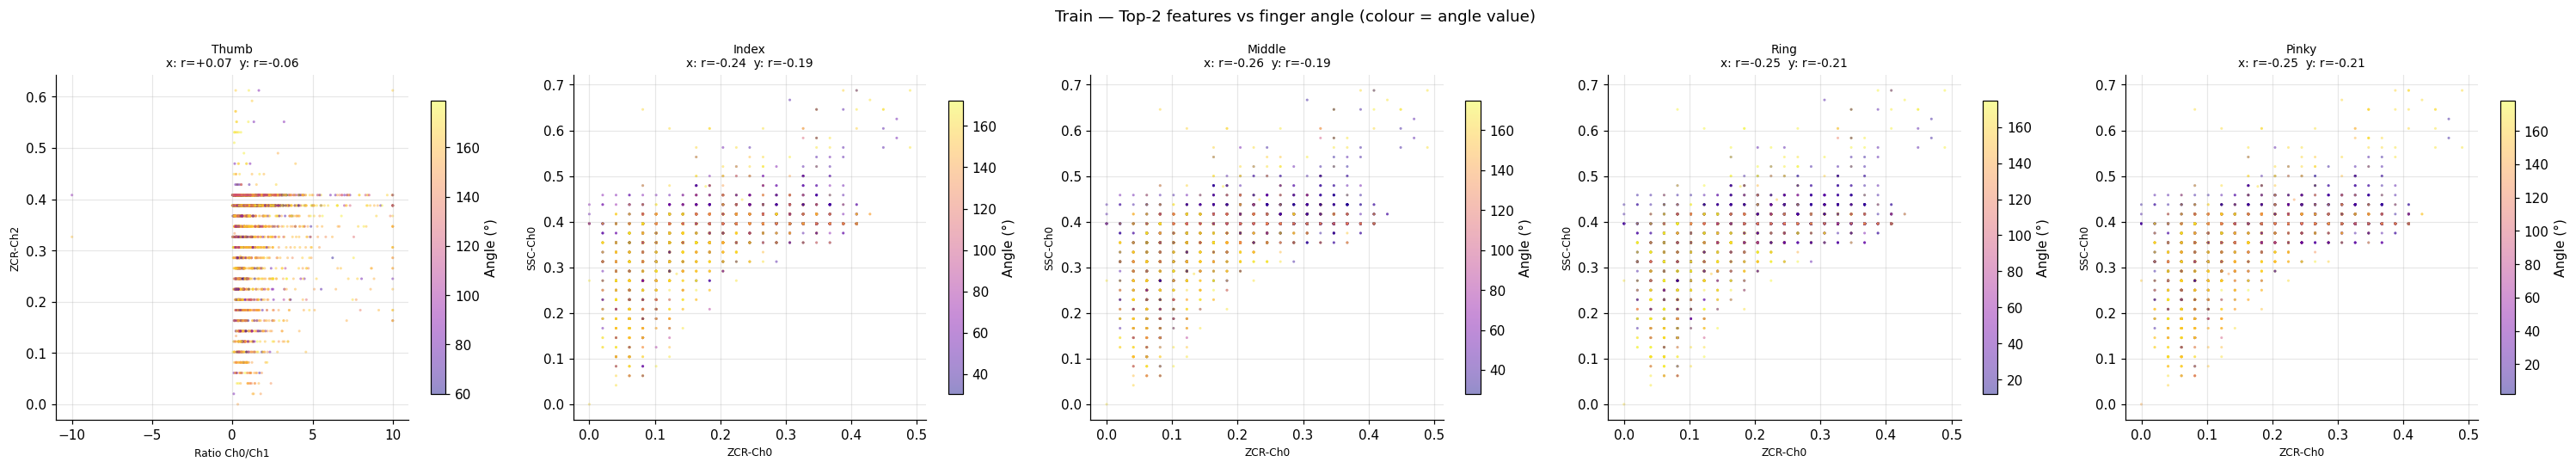

In [42]:
TOP_SCATTER = 2   # top-N features per finger to pair on x/y axes

fig, axes = plt.subplots(1, len(FINGER_NAMES),
                         figsize=(5.5 * len(FINGER_NAMES), 5))
fig.suptitle(
    f'{DATASET_LABEL} — Top-2 features vs finger angle (colour = angle value)',
    fontsize=12)

for ai, (fname, fc) in enumerate(zip(FINGER_NAMES, FINGER_COLORS)):
    abs_c   = np.abs(corr[ai])
    top_idx = np.argsort(abs_c)[::-1][:TOP_SCATTER]
    fi0, fi1 = top_idx[0], top_idx[1]

    # subsample for speed if dataset is large
    step  = max(1, len(feat_matrix) // 4000)
    x_vals = feat_matrix[::step, fi0]
    y_vals = feat_matrix[::step, fi1]
    c_vals = angles[::step, ai]

    ax = axes[ai]
    sc = ax.scatter(x_vals, y_vals, c=c_vals, cmap='plasma',
                    s=4, alpha=0.45, linewidths=0)
    plt.colorbar(sc, ax=ax, label='Angle (°)', shrink=0.85)
    ax.set_xlabel(feat_col_names[fi0], fontsize=8)
    ax.set_ylabel(feat_col_names[fi1], fontsize=8)
    ax.set_title(
        f'{fname}\n'
        f'x: r={corr[ai,fi0]:+.2f}  y: r={corr[ai,fi1]:+.2f}',
        fontsize=9)

plt.tight_layout()
plt.show()

## 16 · Per-channel amplitude distribution (boxplots)

Compares the amplitude statistics across preprocessing stages. Useful to check that demeaning and envelope extraction are behaving as expected.

C:\Users\Gabri\AppData\Local\Temp\ipykernel_7928\4090031129.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(bp_data, labels=stage_names, patch_artist=True,
C:\Users\Gabri\AppData\Local\Temp\ipykernel_7928\4090031129.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(bp_data, labels=stage_names, patch_artist=True,
C:\Users\Gabri\AppData\Local\Temp\ipykernel_7928\4090031129.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(bp_data, labels=stage_names, patch_artist=True,
C:\Users\Gabri\AppData\Local\Temp\ipykernel_7928\4090031129.py:9: MatplotlibDeprecationWarning: T

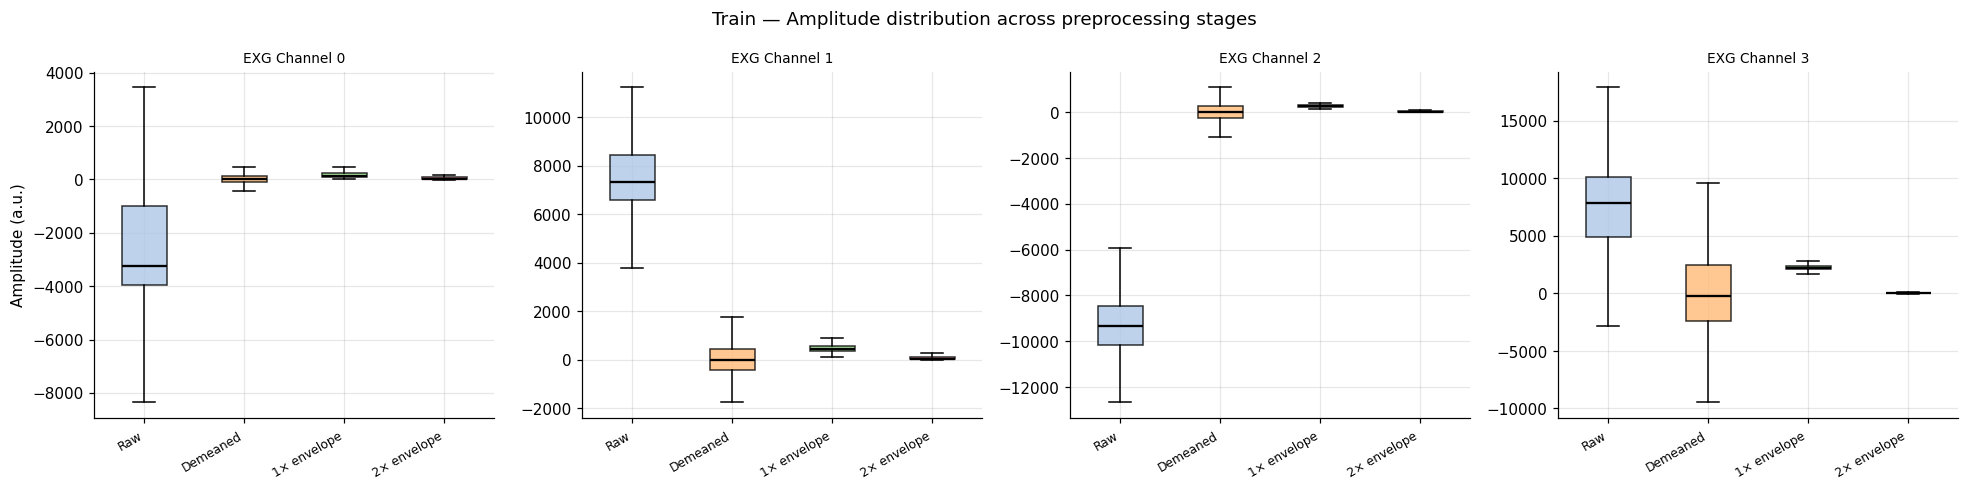

In [43]:
stage_data  = [raw, demeaned, env1, env2]
stage_names = ['Raw', 'Demeaned', '1× envelope', '2× envelope']

fig, axes = plt.subplots(1, n_ch, figsize=(4.5 * n_ch, 4.5), sharey=False)
fig.suptitle(f'{DATASET_LABEL} — Amplitude distribution across preprocessing stages', fontsize=12)

for ch, ax in enumerate(axes):
    bp_data = [s[:, ch] for s in stage_data]
    bp = ax.boxplot(bp_data, labels=stage_names, patch_artist=True,
                    showfliers=False, medianprops={'color': 'black', 'linewidth': 1.5})
    for patch, color in zip(bp['boxes'],
                             ['#aec7e8', '#ffbb78', '#98df8a', '#ff9896']):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    ax.set_title(EMG_CHANNELS[ch], fontsize=9)
    ax.set_xticklabels(stage_names, rotation=30, ha='right', fontsize=8)
    if ch == 0:
        ax.set_ylabel('Amplitude (a.u.)')

plt.tight_layout()
plt.show()

## 17 · Segment inspector

Zoom into any slice and see **all** signal layers + features + angles stacked in a single figure. Useful for manual event inspection.

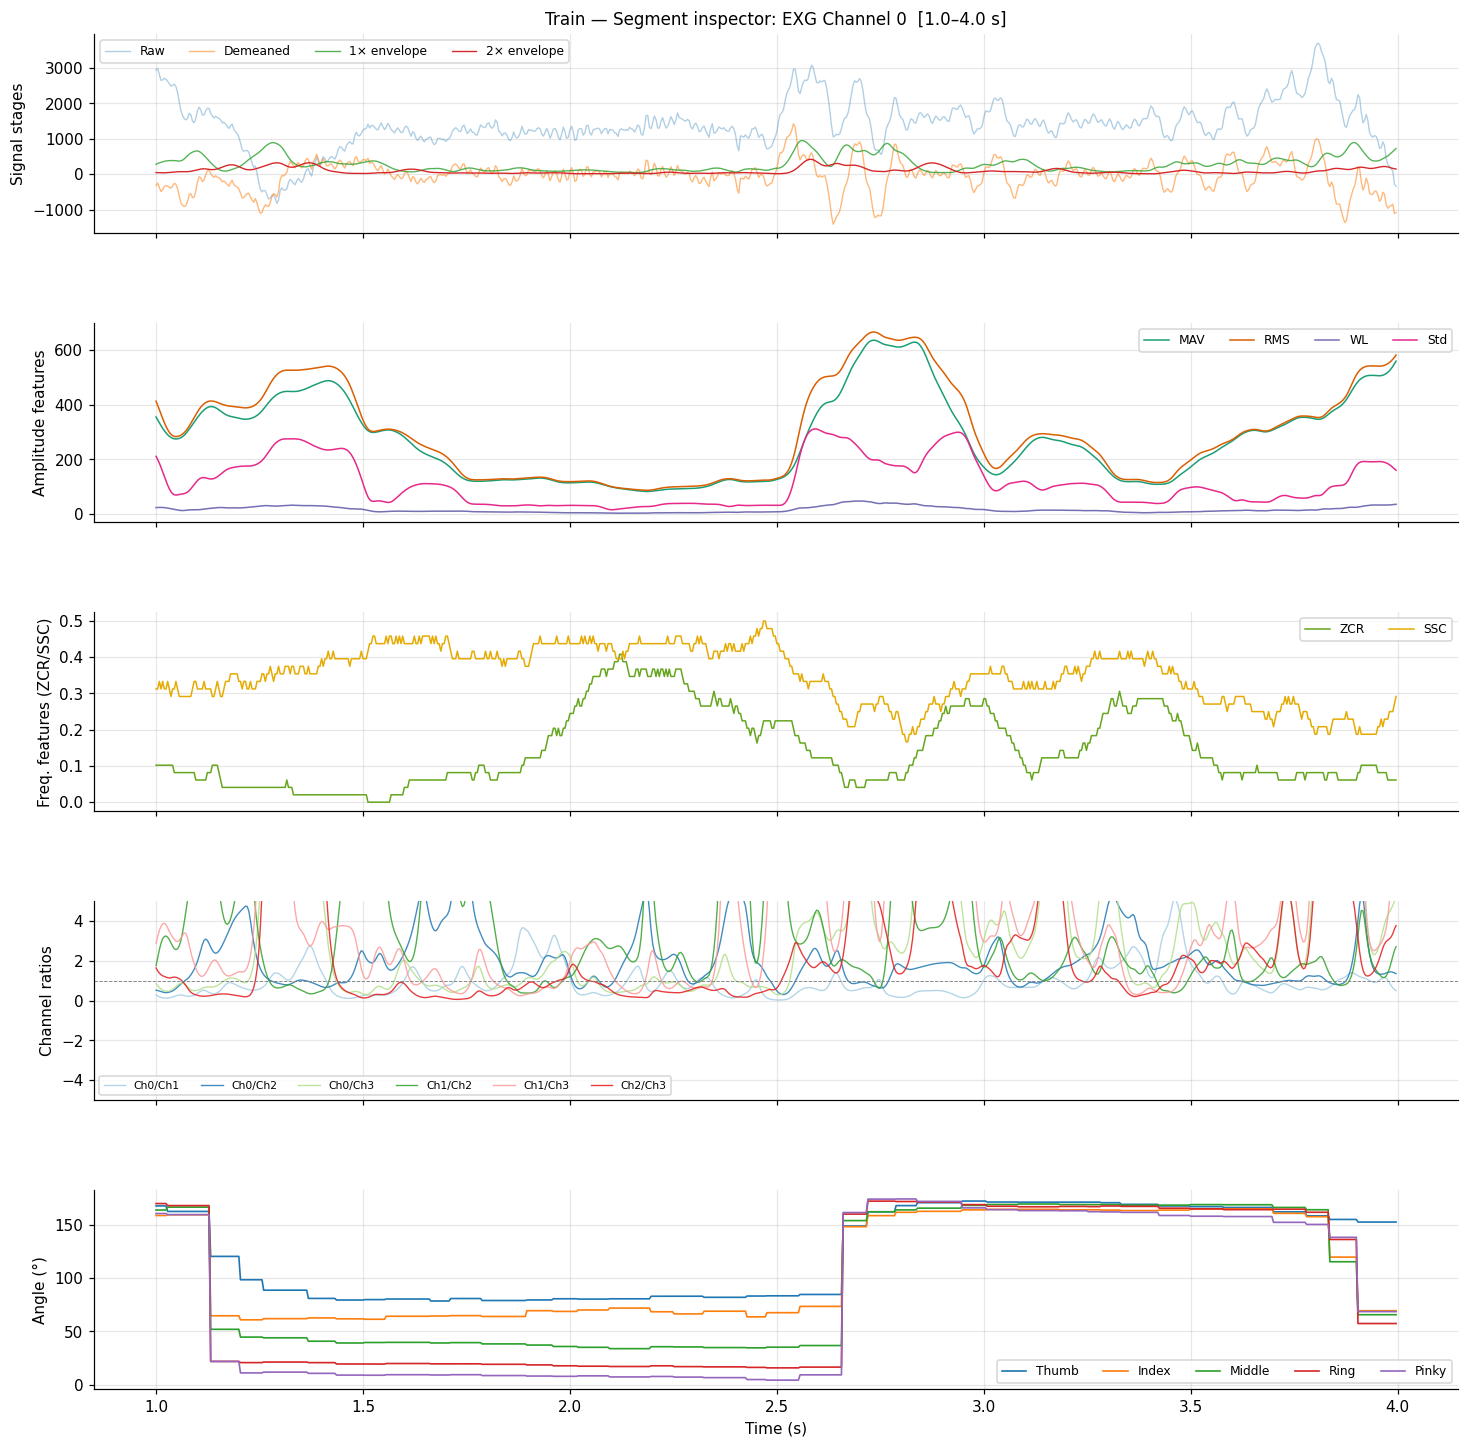

In [44]:
# ── configure segment ────────────────────────────────────────────────────────
SEG_START_S = 1.0    # start of segment (seconds)
SEG_END_S   = 4.0    # end   of segment (seconds)
INSP_CH     = 0      # which EMG channel to inspect

i0, i1 = int(SEG_START_S * FS), int(SEG_END_S * FS)
t_seg  = time_s[i0:i1]

fig = plt.figure(figsize=(16, 16))
gs  = gridspec.GridSpec(5, 1, hspace=0.45)

# — 1: signal stages ─────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
for data, label, alpha in [
    (raw,      'Raw',         0.35),
    (demeaned, 'Demeaned',    0.55),
    (env1,     '1× envelope', 0.80),
    (env2,     '2× envelope', 1.00),
]:
    ax1.plot(t_seg, data[i0:i1, INSP_CH], label=label, alpha=alpha, linewidth=0.9)
ax1.set_title(f'{DATASET_LABEL} — Segment inspector: {EMG_CHANNELS[INSP_CH]}  [{SEG_START_S}–{SEG_END_S} s]',
              fontsize=11)
ax1.set_ylabel('Signal stages')
ax1.legend(ncol=4, fontsize=8)

# — 2: amplitude features ─────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1], sharex=ax1)
for fdata, fname, fcolor, _ in FEATURES[:4]:   # MAV, RMS, WL, Std
    ax2.plot(t_seg, fdata[i0:i1, INSP_CH], label=fname.split('(')[0].strip(),
             color=fcolor, linewidth=1.0)
ax2.set_ylabel('Amplitude features')
ax2.legend(ncol=4, fontsize=8)

# — 3: frequency features ─────────────────────────────────────────────────────
ax3 = fig.add_subplot(gs[2], sharex=ax1)
ax3.plot(t_seg, F_ZCR[i0:i1, INSP_CH], label='ZCR', color='#66a61e', linewidth=1.0)
ax3.plot(t_seg, F_SSC[i0:i1, INSP_CH], label='SSC', color='#e6ab02', linewidth=1.0)
ax3.set_ylabel('Freq. features (ZCR/SSC)')
ax3.legend(ncol=2, fontsize=8)

# — 4: pairwise ratios ────────────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[3], sharex=ax1)
for k, (label, c) in enumerate(zip(ratio_labels, RATIO_COLORS)):
    ax4.plot(t_seg, ratios[i0:i1, k], label=label, color=c, linewidth=0.9, alpha=0.85)
ax4.axhline(1.0, color='gray', linewidth=0.6, linestyle='--')
ax4.set_ylim(-5, 5)
ax4.set_ylabel('Channel ratios')
ax4.legend(ncol=6, fontsize=7)

# — 5: finger angles ──────────────────────────────────────────────────────────
ax5 = fig.add_subplot(gs[4], sharex=ax1)
for i, (name, c) in enumerate(zip(FINGER_NAMES, FINGER_COLORS)):
    ax5.plot(t_seg, angles[i0:i1, i], label=name, color=c, linewidth=1.1)
ax5.set_ylabel('Angle (°)')
ax5.set_xlabel('Time (s)')
ax5.legend(ncol=5, fontsize=8)

for ax in [ax1, ax2, ax3, ax4]:
    plt.setp(ax.get_xticklabels(), visible=False)

plt.show()

## 18 · Top correlated features per finger

Ranks features by |Pearson r| for each finger — quick reference for feature selection.

In [45]:
TOP_N = 8

for ai, fname in enumerate(FINGER_NAMES):
    abs_corr = np.abs(corr[ai])
    top_idx  = np.argsort(abs_corr)[::-1][:TOP_N]
    print(f'\n{fname}:')
    for rank, fi in enumerate(top_idx, 1):
        print(f'  {rank}. {feat_col_names[fi]:<22}  r = {corr[ai, fi]:+.3f}')


Thumb:
  1. Ratio Ch0/Ch1           r = +0.073
  2. ZCR-Ch2                 r = -0.064
  3. Ratio Ch1/Ch2           r = -0.060
  4. Ratio Ch0/Ch3           r = +0.055
  5. SSC-Ch0                 r = -0.051
  6. MAV-Ch3                 r = -0.045
  7. Ratio Ch1/Ch3           r = -0.044
  8. MAV-Ch0                 r = +0.043

Index:
  1. ZCR-Ch0                 r = -0.237
  2. SSC-Ch0                 r = -0.189
  3. ZCR-Ch1                 r = -0.167
  4. ZCR-Ch2                 r = -0.160
  5. MAV-Ch0                 r = +0.141
  6. WL-Ch0                  r = +0.140
  7. RMS-Ch0                 r = +0.140
  8. Std-Ch0                 r = +0.130

Middle:
  1. ZCR-Ch0                 r = -0.264
  2. SSC-Ch0                 r = -0.193
  3. ZCR-Ch1                 r = -0.187
  4. ZCR-Ch2                 r = -0.161
  5. WL-Ch0                  r = +0.147
  6. MAV-Ch0                 r = +0.144
  7. RMS-Ch0                 r = +0.144
  8. Ratio Ch0/Ch3           r = +0.139

Ring:
  1. ZCR

## 19 · Cross-dataset comparison (Train vs Test)

Quick sanity check: PSD and angle distributions should look similar; big differences indicate covariate shift.

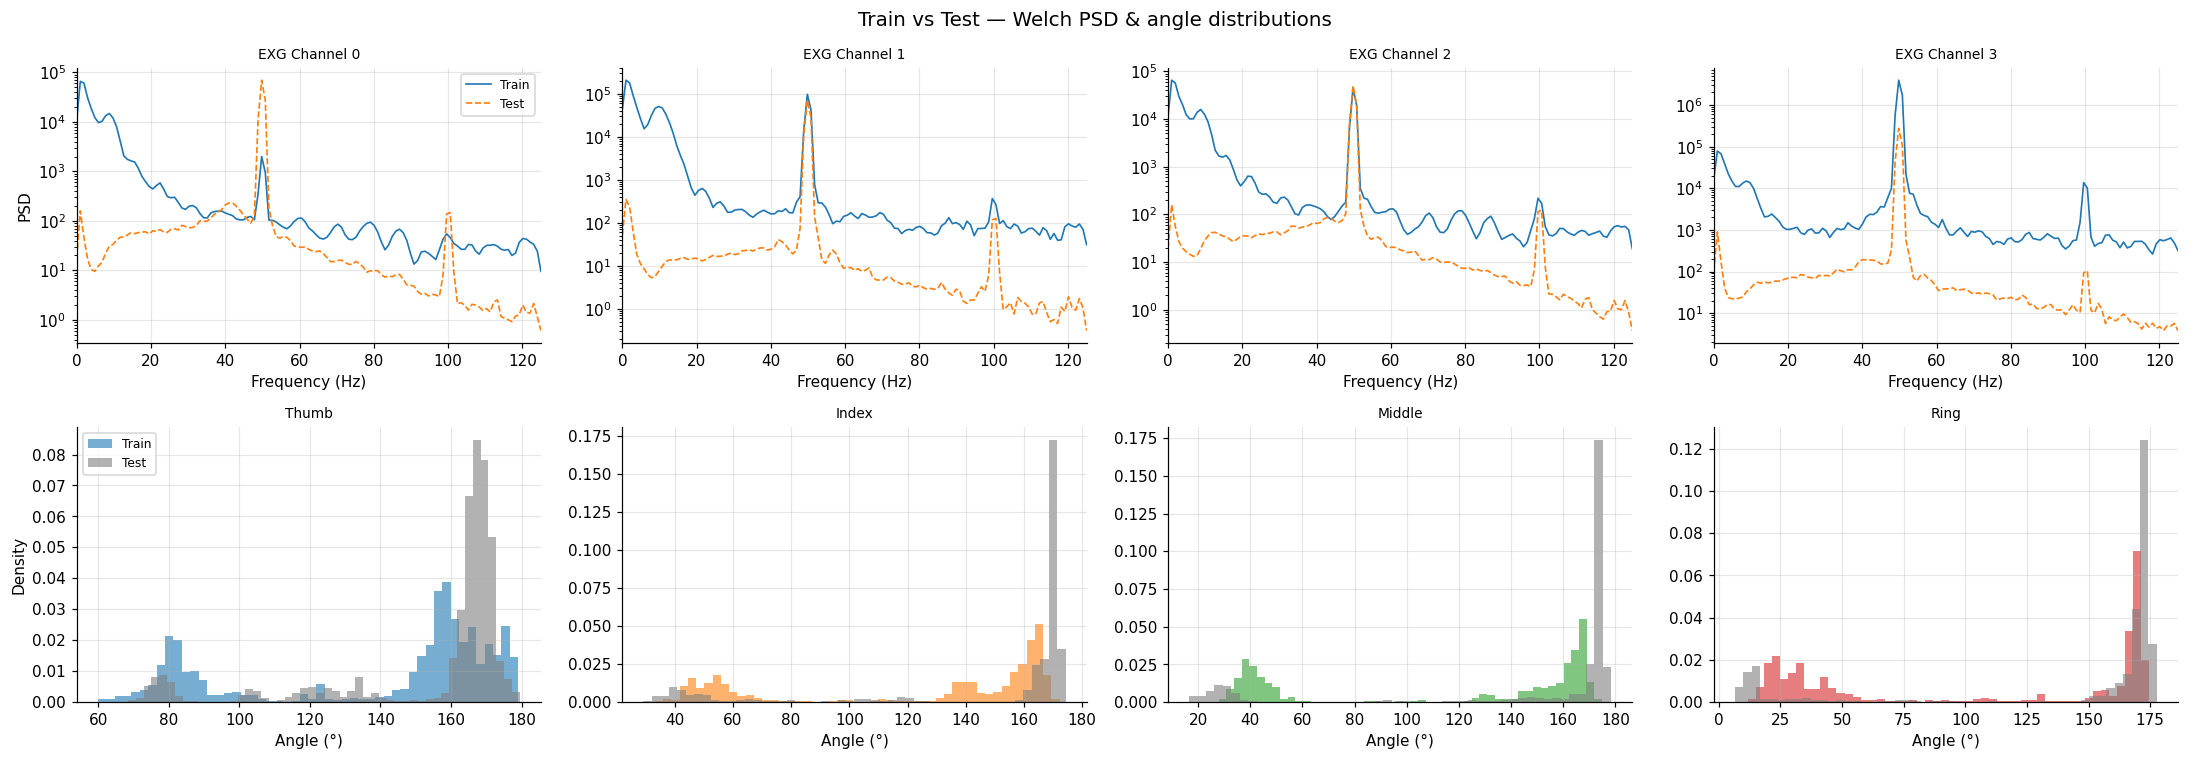

In [46]:
train_raw = train_df[EMG_CHANNELS].values.astype(np.float64)
test_raw  = test_df[EMG_CHANNELS].values.astype(np.float64)

fig, axes = plt.subplots(2, n_ch, figsize=(5 * n_ch, 7))
fig.suptitle('Train vs Test — Welch PSD & angle distributions', fontsize=13)

for ch in range(n_ch):
    # PSD
    for data, label, ls in [(train_raw[:, ch], 'Train', '-'), (test_raw[:, ch], 'Test', '--')]:
        f, pxx = welch(data, fs=FS, nperseg=256)
        axes[0, ch].semilogy(f, pxx, label=label, ls=ls, linewidth=1.1)
    axes[0, ch].set_title(EMG_CHANNELS[ch], fontsize=9)
    axes[0, ch].set_xlim(0, FS / 2)
    axes[0, ch].set_xlabel('Frequency (Hz)')
    if ch == 0:
        axes[0, ch].set_ylabel('PSD')
        axes[0, ch].legend(fontsize=8)

# Angle distributions
for ai, (fname, fc) in enumerate(zip(FINGER_NAMES, FINGER_COLORS)):
    col = ANGLE_COLS[ai]
    if ai < n_ch:
        axes[1, ai].hist(train_df[col], bins=50, alpha=0.6, label='Train', color=fc, density=True)
        axes[1, ai].hist(test_df[col],  bins=50, alpha=0.6, label='Test',  color='gray', density=True)
        axes[1, ai].set_title(fname, fontsize=9)
        axes[1, ai].set_xlabel('Angle (°)')
        if ai == 0:
            axes[1, ai].set_ylabel('Density')
            axes[1, ai].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 20 · Cross-session amplitude mismatch & normalisation fix

This section reproduces the diagnostic that explained why some models failed cross-session while others did not, and verifies the fix that was applied.

**Background:** Models 8 and 9 (FullFeature / Multi-Rate, using raw EMG → single-pass preprocessing) scored near-zero or negative accuracy cross-session. Model 3 (Windowed Statistics, using double-pass preprocessed EMG) scored 65–75% on the same data. The root cause was traced to a single number: Channel 3's test features landing **−6.3 standard deviations** from the training distribution after z-score normalisation — making the channel invisible to the model.

**Fix:** Per-channel z-score normalisation of raw EMG using training statistics only, applied before any feature extraction (`emg_model_comparison.py`, main()).

### 20a · The problem — raw signal amplitude differs dramatically between sessions

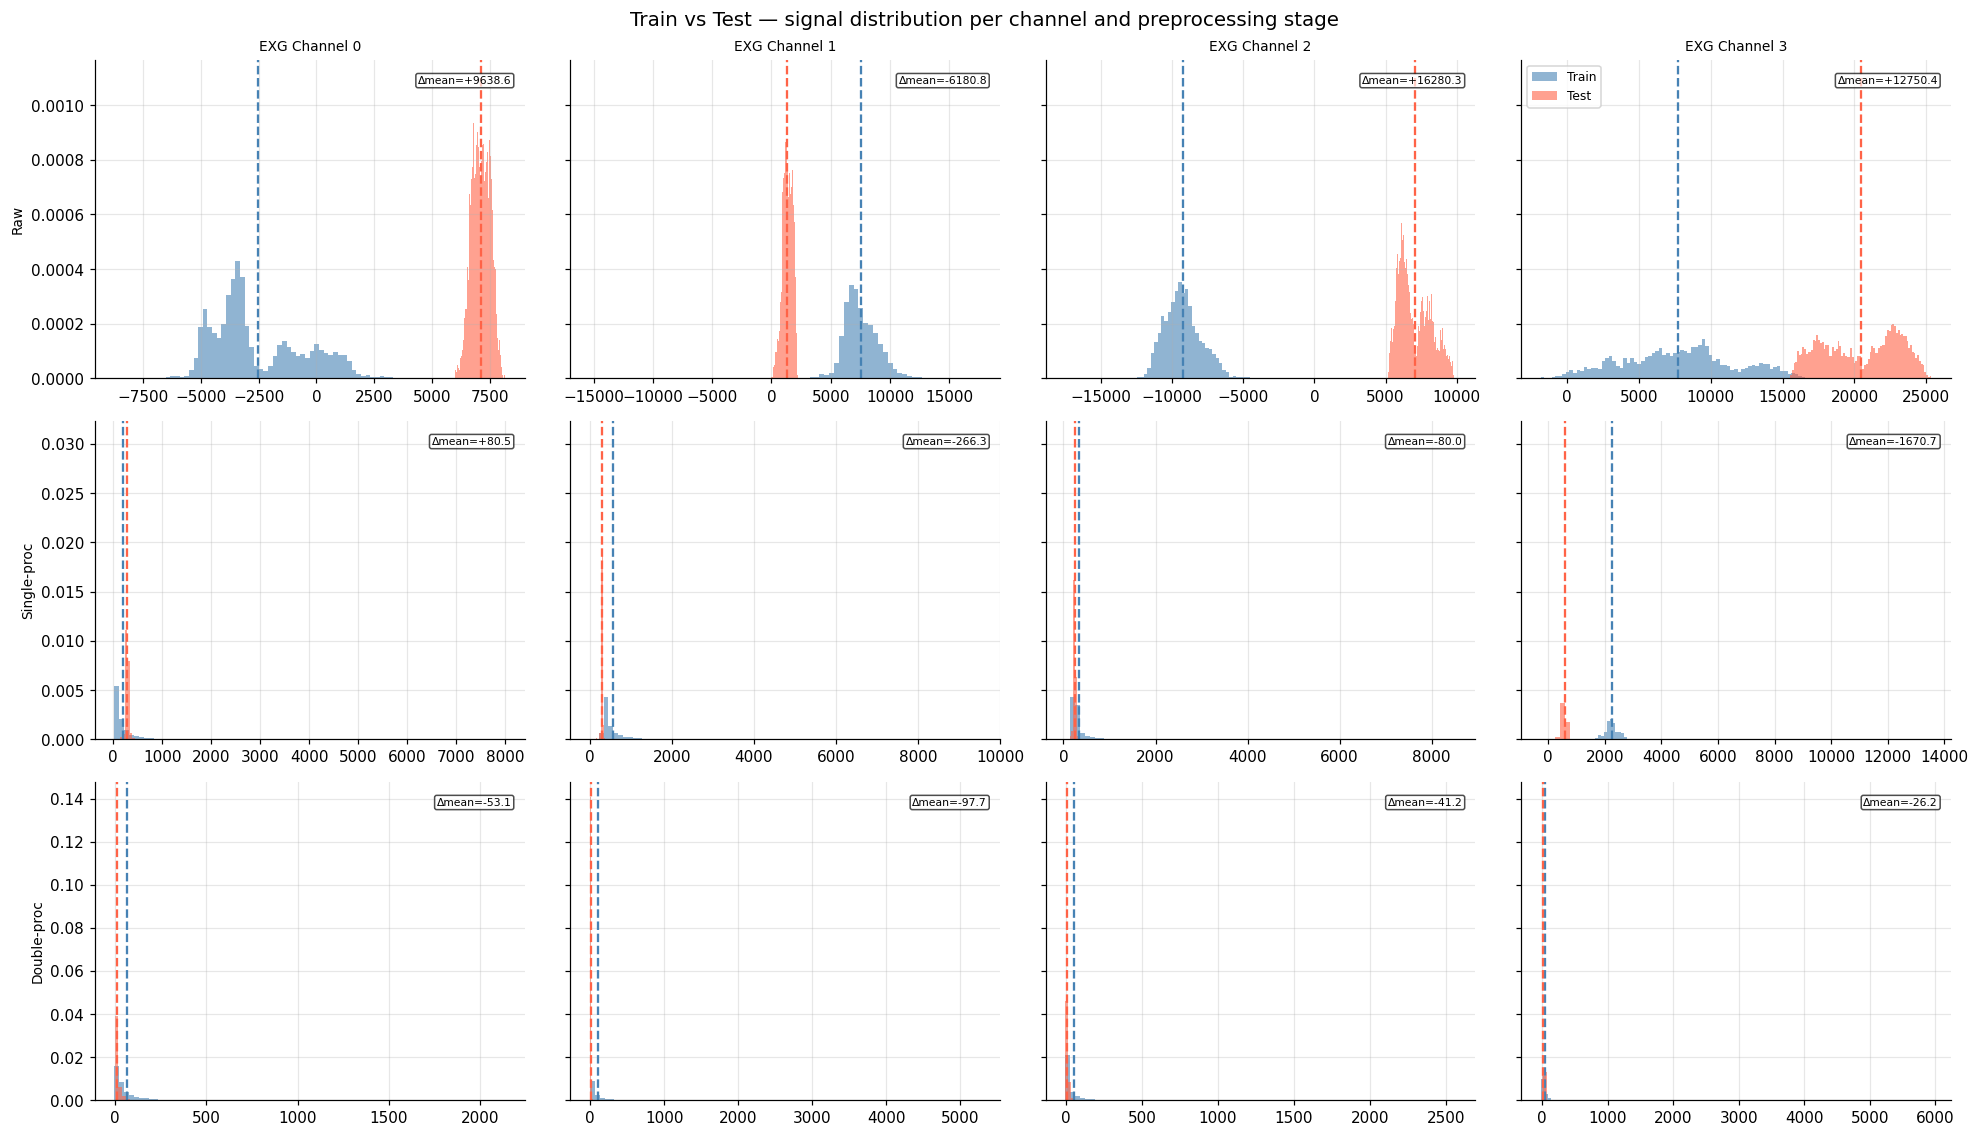


Stage          Metric EXG Channel 0   EXG Channel 1   EXG Channel 2   EXG Channel 3 
Raw            tr mean       -2536.08         7539.25        -9238.15         7743.97
               te mean        7102.89         1357.55         7043.24        20487.04
Raw            tr std        2010.53         1459.80         1329.06         3894.08
               te std         390.01          418.95         1128.24         2639.27
Single-proc    tr mean         212.80          565.50          328.75         2251.33
               te mean         293.25          298.95          248.69          580.43
Single-proc    tr std         299.50          427.03          275.74          263.94
               te std          55.03           18.56           46.95          179.59
Double-proc    tr mean          66.45          103.93           51.15           43.43
               te mean          13.42            6.30           10.08           17.23
Double-proc    tr std         118.81          190.76      

In [47]:
# Recompute preprocessing stages for both sessions
train_raw_20 = train_df[EMG_CHANNELS].values.astype(np.float64)
test_raw_20  = test_df[EMG_CHANNELS].values.astype(np.float64)

single_tr = preprocess_emg(train_raw_20)
single_te = preprocess_emg(test_raw_20)
double_tr = preprocess_emg(single_tr)
double_te = preprocess_emg(single_te)

stages = [
    ('Raw',           train_raw_20, test_raw_20),
    ('Single-proc',   single_tr,    single_te),
    ('Double-proc',   double_tr,    double_te),
]

fig, axes = plt.subplots(len(stages), n_ch, figsize=(4.5 * n_ch, 3.5 * len(stages)),
                          sharey='row')
fig.suptitle('Train vs Test — signal distribution per channel and preprocessing stage',
             fontsize=13)

for row, (stage_name, tr, te) in enumerate(stages):
    for ch in range(n_ch):
        ax = axes[row, ch]
        step = max(1, len(tr) // 5000)
        data_tr = tr[::step, ch]
        data_te = te[::step, ch]

        ax.hist(data_tr, bins=80, alpha=0.6, color='steelblue', density=True,
                label='Train', linewidth=0)
        ax.hist(data_te, bins=80, alpha=0.6, color='tomato',    density=True,
                label='Test',  linewidth=0)

        ax.axvline(data_tr.mean(), color='steelblue', linewidth=1.5, linestyle='--')
        ax.axvline(data_te.mean(), color='tomato',    linewidth=1.5, linestyle='--')

        if row == 0:
            ax.set_title(EMG_CHANNELS[ch], fontsize=9)
        if ch == 0:
            ax.set_ylabel(stage_name, fontsize=9)
        if row == 0 and ch == n_ch - 1:
            ax.legend(fontsize=8)

        diff = data_te.mean() - data_tr.mean()
        ax.text(0.97, 0.95, f'Δmean={diff:+.1f}', transform=ax.transAxes,
                fontsize=7, ha='right', va='top',
                color='black', bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7))

plt.tight_layout()
plt.show()

print(f"\n{'Stage':<14} {'Metric':<6} " +
      "  ".join(f"{c:<14}" for c in EMG_CHANNELS))
for stage_name, tr, te in stages:
    for metric, fn in [('mean', np.mean), ('std', np.std)]:
        vals_tr = [fn(tr[:, i]) for i in range(n_ch)]
        vals_te = [fn(te[:, i]) for i in range(n_ch)]
        print(f"{stage_name:<14} tr {metric:<3} " +
              "  ".join(f"{v:>14.2f}" for v in vals_tr))
        print(f"{'':14} te {metric:<3} " +
              "  ".join(f"{v:>14.2f}" for v in vals_te))

### 20b · Quantifying the mismatch — z-score offset per preprocessing stage

For `normalize_features()` to work cross-session, test features must fall within the training distribution. The bar below shows how many standard deviations the **test session mean** is from the **training session mean**, for each channel and preprocessing stage.

Values beyond ±2 (dashed lines) mean the model is asked to generalise outside its training range.

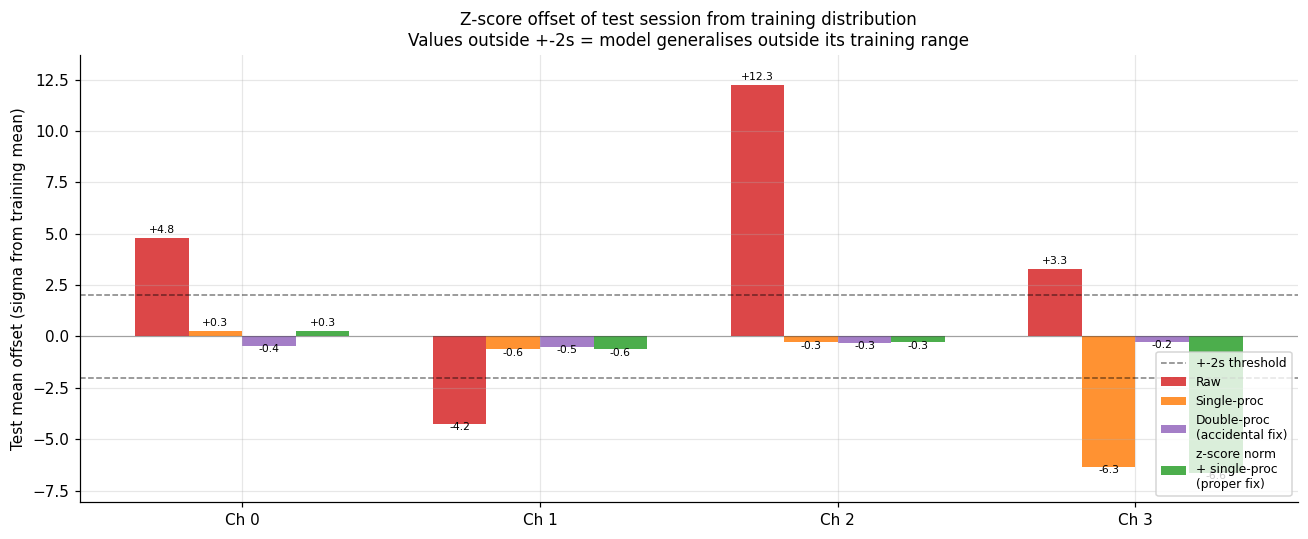

Summary of z-score offsets:
Stage                                         Ch0       Ch1       Ch2       Ch3
  Raw                                       +4.79     -4.23    +12.25     +3.27
  Single-proc                               +0.27     -0.62     -0.29     -6.33
  Double-proc (accidental fix)              -0.45     -0.51     -0.32     -0.25
  z-score norm + single-proc (proper fix)    +0.27     -0.63     -0.29     -6.62


In [48]:
# Apply the fix: z-score normalisation using train statistics only
emg_train_mean = train_raw_20.mean(axis=0, keepdims=True)
emg_train_std  = train_raw_20.std(axis=0, keepdims=True) + 1e-8
train_norm_raw = (train_raw_20 - emg_train_mean) / emg_train_std
test_norm_raw  = (test_raw_20  - emg_train_mean) / emg_train_std

single_tr_fixed = preprocess_emg(train_norm_raw)
single_te_fixed = preprocess_emg(test_norm_raw)

all_stages = [
    ('Raw',             train_raw_20,    test_raw_20),
    ('Single-proc',     single_tr,       single_te),
    ('Double-proc\n(accidental fix)', double_tr, double_te),
    ('z-score norm\n+ single-proc\n(proper fix)', single_tr_fixed, single_te_fixed),
]

x = np.arange(n_ch)
width = 0.18
stage_colors = ['#d62728', '#ff7f0e', '#9467bd', '#2ca02c']

fig, ax = plt.subplots(figsize=(12, 5))

for i, (label, tr, te) in enumerate(all_stages):
    zscores = [(te[:, ch].mean() - tr[:, ch].mean()) / (tr[:, ch].std() + 1e-8)
               for ch in range(n_ch)]
    offset = (i - len(all_stages) / 2 + 0.5) * width
    bars = ax.bar(x + offset, zscores, width, label=label,
                  color=stage_colors[i], alpha=0.85)
    for bar, z in zip(bars, zscores):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + (0.15 if z >= 0 else -0.4),
                f'{z:+.1f}', ha='center', va='bottom', fontsize=7)

ax.axhline( 2, color='black', linewidth=1, linestyle='--', alpha=0.5, label='+-2s threshold')
ax.axhline(-2, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.axhline( 0, color='black', linewidth=0.8, alpha=0.3)

ax.set_xticks(x)
ax.set_xticklabels([f'Ch {i}' for i in range(n_ch)], fontsize=10)
ax.set_ylabel('Test mean offset (sigma from training mean)', fontsize=10)
ax.set_title('Z-score offset of test session from training distribution\n'
             'Values outside +-2s = model generalises outside its training range', fontsize=11)
ax.legend(fontsize=8, loc='lower right')
ax.set_ylim(min(-7.5, ax.get_ylim()[0] - 0.5), max(3.5, ax.get_ylim()[1] + 0.5))

plt.tight_layout()
plt.show()

print("Summary of z-score offsets:")
print(f"{'Stage':<40} " + "  ".join(f"{'Ch'+str(i):>8}" for i in range(n_ch)))
for label, tr, te in all_stages:
    label_clean = label.replace('\n', ' ')
    zscores = [(te[:, ch].mean() - tr[:, ch].mean()) / (tr[:, ch].std() + 1e-8)
               for ch in range(n_ch)]
    print(f"  {label_clean:<38} " + "  ".join(f"{z:>+8.2f}" for z in zscores))

### 20c · Feature distribution overlap — two distinct inter-session problems

The windowed-mean of the single-pass envelope is used as a representative feature.
Bhattacharyya overlap (0 = no overlap, 1 = identical) measures how much of the test
feature distribution falls inside the training distribution.

**20b and 20c measure different things and should be read together:**

| What is measured | Fixed by z-score norm (train stats)? | Explanation |
|---|---|---|
| **20b — mean z-score offset** | Yes | Z-score removes inter-session DC/mean difference |
| **20c — full distribution overlap** | **No** (for Ch0/Ch1/Ch3) | Z-score fixes location but not scale |

**Why z-score cannot fix amplitude scale:**

`test_norm = (test_raw − train_mean) / train_std`

- `train_norm` std = 1.0 (by construction)
- `test_norm` std = **test_std_raw / train_std_raw** — if the sessions have different signal amplitudes, this ratio is not 1

If Ch3 test amplitude is ≈ 0.26× train, after z-scoring the test signal still has only 26% of
train's amplitude. The envelope will be ≈ 0.26× lower. The distributions stay at different
positions → same poor overlap as the un-normalised case. This is why scenario 3 looks
identical to scenario 1 for Ch3.

**Why Ch1 overlap got *worse* after z-score (0.423 → 0.247):** If Ch1's raw std is dominated
by a large DC offset rather than AC muscle activity, dividing by that large `train_std`
compresses the AC components in both sessions — but unequally — making the resulting
envelopes *less* aligned than the originals.

**Why double-proc fixes 20c:** The second pass subtracts the running mean of the envelope,
making features proportional to *relative* activation variation rather than absolute level.
Both sessions show similar open/close dynamics regardless of absolute scale → high overlap.

**Four scenarios — 3 and 4 reflect what the current code actually runs:**

| Scenario | What it models | Problem fixed |
|---|---|---|
| 1: Single-proc | Old models 7/8/9 | Neither |
| 2: Double-proc | Old models 1–6 (model 3) | Scale only (via relative normalization) |
| 3: z-score + single-proc | **Current** models 7/8/9 | Mean/DC only |
| 4: z-score + double-proc | **Current** models 1–6 | Both mean and scale |

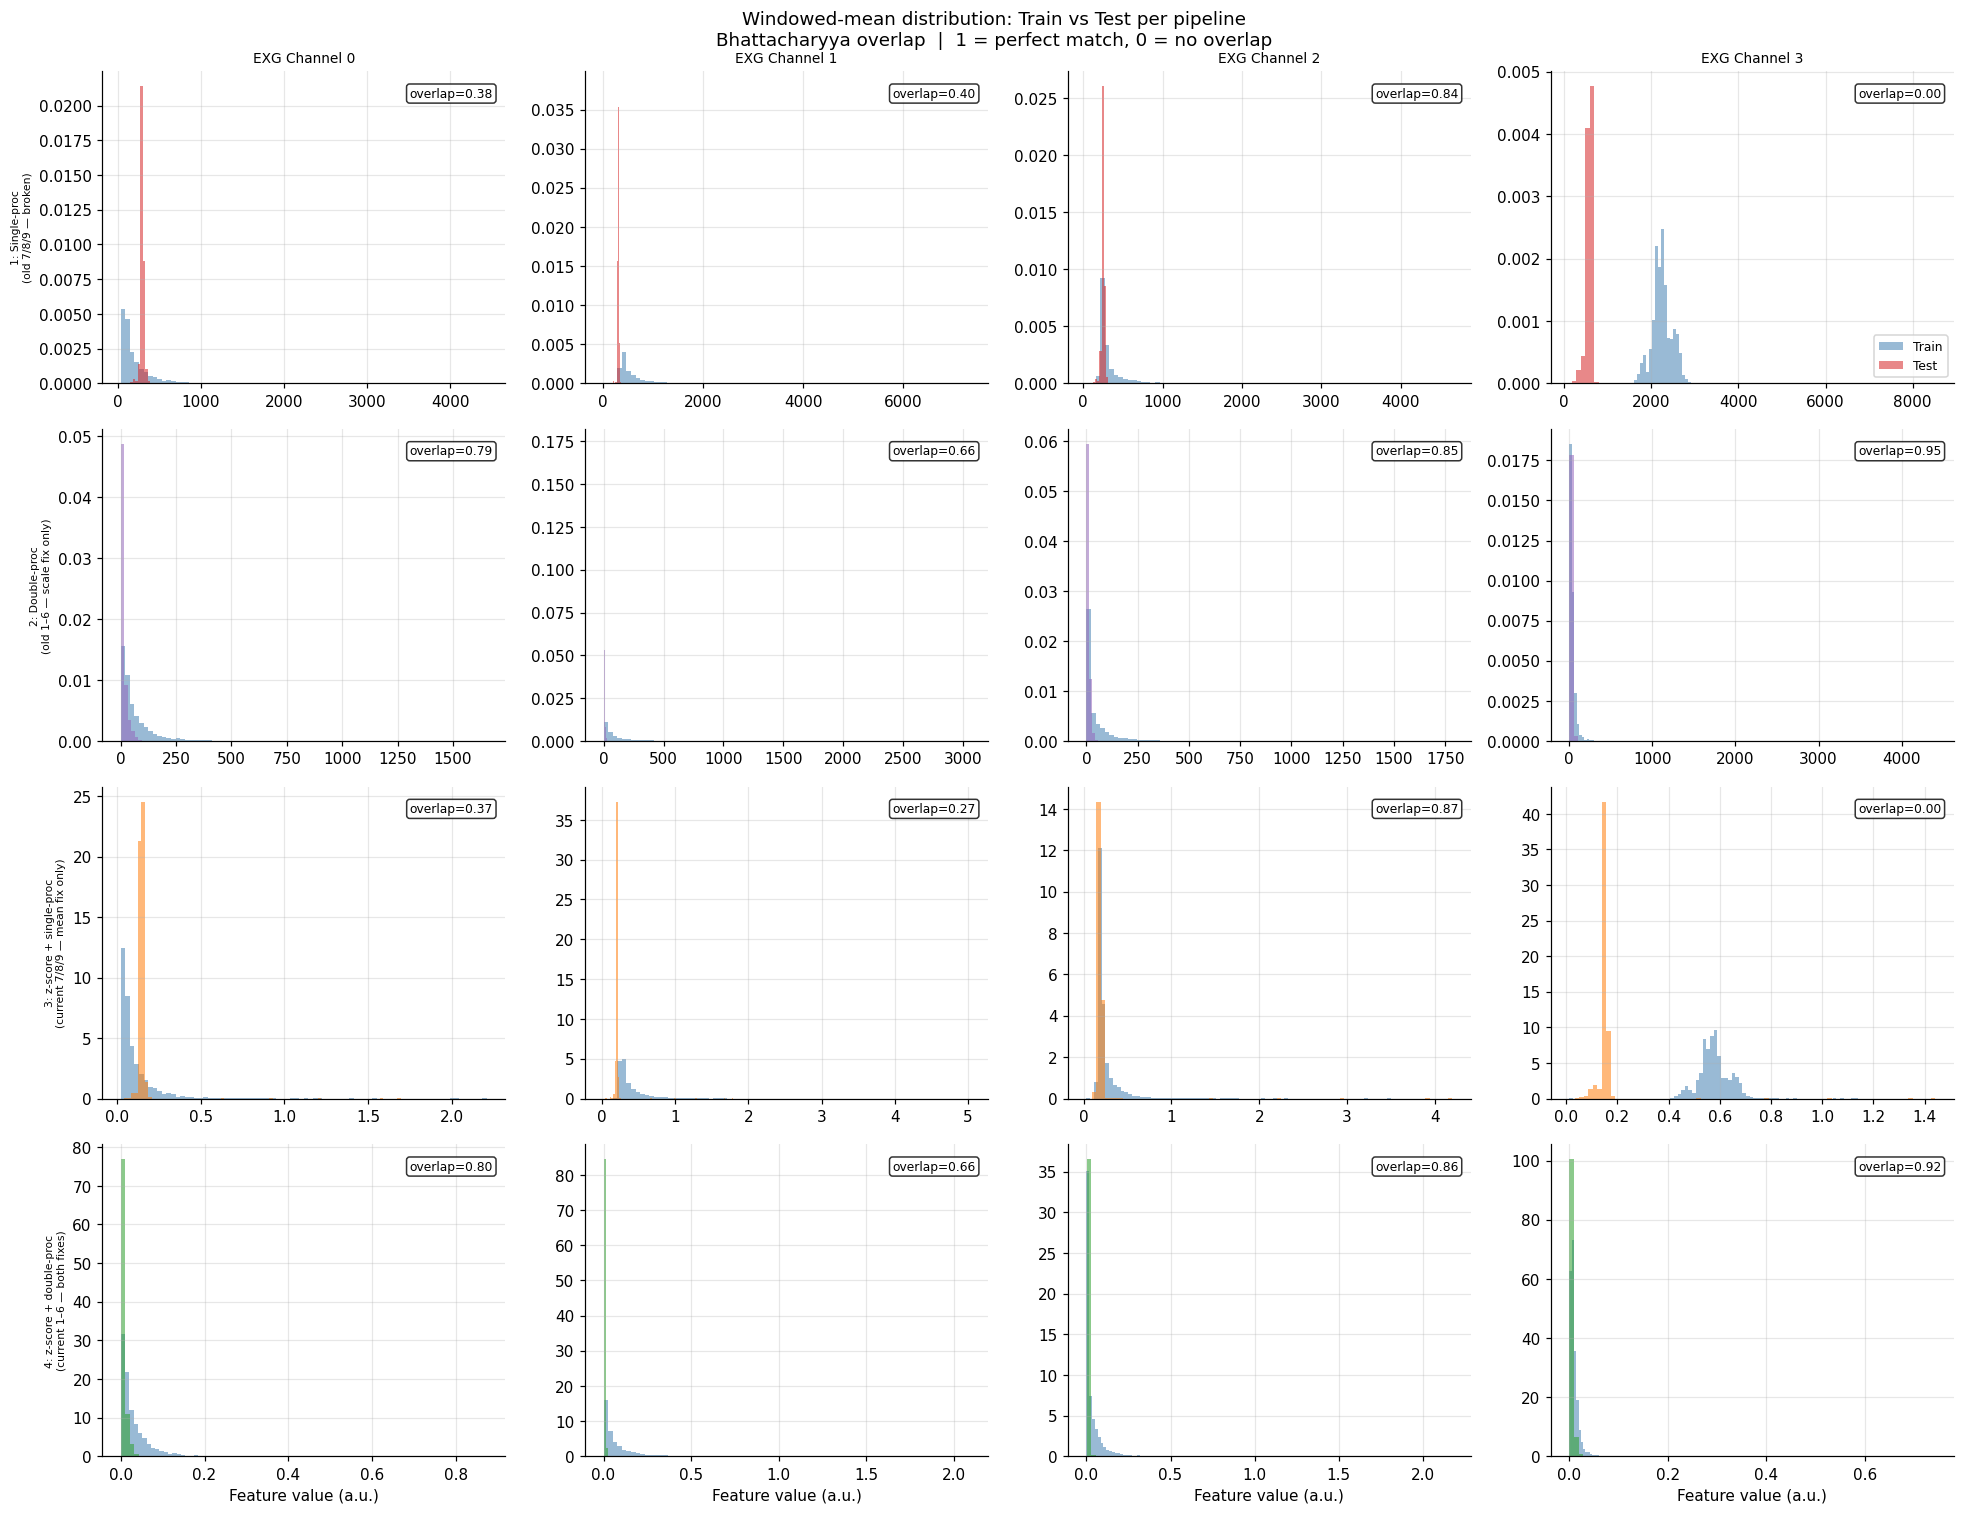


Scenario                                                        Ch0       Ch1       Ch2       Ch3
  1: Single-proc (old 7/8/9 — broken)                         0.377     0.423     0.841     0.012
  2: Double-proc (old 1–6 — scale fix only)                   0.801     0.675     0.855     0.950
  3: z-score + single-proc (current 7/8/9 — mean fix only)    0.373     0.247     0.860     0.013
  4: z-score + double-proc (current 1–6 — both fixes)         0.804     0.676     0.863     0.922

Amplitude scale ratio test/train (std of windowed-mean feature):
Scenario                                                        Ch0       Ch1       Ch2       Ch3
  1: Single-proc (old 7/8/9 — broken)                         0.200     0.047     0.193     0.738
  2: Double-proc (old 1–6 — scale fix only)                   0.348     0.029     0.269     1.226
  3: z-score + single-proc (current 7/8/9 — mean fix only)    0.272     0.152     0.508     0.525
  4: z-score + double-proc (current 1–6 — both fixe

In [49]:
def windowed_mean(x, win=50):
    """Causal rolling mean."""
    N, C = x.shape
    out = np.zeros((N, C), dtype=np.float32)
    for i in range(N):
        w = x[max(0, i - win + 1):i + 1, :]
        out[i] = np.mean(w, axis=0)
    return out


def bhattacharyya_overlap(a, b, bins=80):
    """Approximate histogram overlap (0=no overlap, 1=identical)."""
    lo = min(a.min(), b.min())
    hi = max(a.max(), b.max())
    if hi == lo:
        return 1.0
    ha, _ = np.histogram(a, bins=bins, range=(lo, hi), density=True)
    hb, _ = np.histogram(b, bins=bins, range=(lo, hi), density=True)
    return float(np.sum(np.sqrt(ha * hb)) * (hi - lo) / bins)


# 4th scenario: z-score then double-proc — what models 1–6 actually run in current code
double_tr_fixed = preprocess_emg(single_tr_fixed)
double_te_fixed = preprocess_emg(single_te_fixed)

feat_single_tr  = windowed_mean(single_tr)
feat_single_te  = windowed_mean(single_te)
feat_double_tr  = windowed_mean(double_tr)
feat_double_te  = windowed_mean(double_te)
feat_fixed_tr   = windowed_mean(single_tr_fixed)
feat_fixed_te   = windowed_mean(single_te_fixed)
feat_fixeddb_tr = windowed_mean(double_tr_fixed)
feat_fixeddb_te = windowed_mean(double_te_fixed)

scenarios = [
    ('1: Single-proc\n(old 7/8/9 — broken)',
     feat_single_tr,  feat_single_te,  '#d62728'),
    ('2: Double-proc\n(old 1–6 — scale fix only)',
     feat_double_tr,  feat_double_te,  '#9467bd'),
    ('3: z-score + single-proc\n(current 7/8/9 — mean fix only)',
     feat_fixed_tr,   feat_fixed_te,   '#ff7f0e'),
    ('4: z-score + double-proc\n(current 1–6 — both fixes)',
     feat_fixeddb_tr, feat_fixeddb_te, '#2ca02c'),
]

fig, axes = plt.subplots(len(scenarios), n_ch,
                          figsize=(4.5 * n_ch, 3.5 * len(scenarios)),
                          sharey=False)
fig.suptitle('Windowed-mean distribution: Train vs Test per pipeline\n'
             'Bhattacharyya overlap  |  1 = perfect match, 0 = no overlap',
             fontsize=12)

for row, (sc_name, feat_tr, feat_te, sc_color) in enumerate(scenarios):
    for ch in range(n_ch):
        ax = axes[row, ch]
        step = max(1, len(feat_tr) // 5000)
        tr_ch = feat_tr[::step, ch]
        te_ch = feat_te[::step, ch]

        ax.hist(tr_ch, bins=80, alpha=0.55, color='steelblue', density=True,
                label='Train', linewidth=0)
        ax.hist(te_ch, bins=80, alpha=0.55, color=sc_color,   density=True,
                label='Test',  linewidth=0)

        overlap = bhattacharyya_overlap(tr_ch, te_ch)
        ax.text(0.97, 0.95, f'overlap={overlap:.2f}',
                transform=ax.transAxes, fontsize=8, ha='right', va='top',
                bbox=dict(boxstyle='round,pad=0.25', fc='white', alpha=0.8))

        if row == 0:
            ax.set_title(EMG_CHANNELS[ch], fontsize=9)
        if ch == 0:
            ax.set_ylabel(sc_name, fontsize=7)
        if row == len(scenarios) - 1:
            ax.set_xlabel('Feature value (a.u.)')
        if row == 0 and ch == n_ch - 1:
            ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'Scenario':<58} " + "  ".join(f"{'Ch'+str(i):>8}" for i in range(n_ch)))
for sc_name, feat_tr, feat_te, _ in scenarios:
    label = sc_name.replace('\n', ' ')
    overlaps = [bhattacharyya_overlap(feat_tr[:, ch], feat_te[:, ch]) for ch in range(n_ch)]
    print(f"  {label:<56} " + "  ".join(f"{v:>8.3f}" for v in overlaps))

# Amplitude scale ratio (test_std / train_std) per scenario — shows why z-score alone is insufficient
print("\nAmplitude scale ratio test/train (std of windowed-mean feature):")
print(f"{'Scenario':<58} " + "  ".join(f"{'Ch'+str(i):>8}" for i in range(n_ch)))
for sc_name, feat_tr, feat_te, _ in scenarios:
    label = sc_name.replace('\n', ' ')
    ratios = [feat_te[::max(1,len(feat_te)//5000), ch].std() /
              (feat_tr[::max(1,len(feat_tr)//5000), ch].std() + 1e-8)
              for ch in range(n_ch)]
    print(f"  {label:<56} " + "  ".join(f"{v:>8.3f}" for v in ratios))
print("  (1.0 = same spread as training; values far from 1 indicate scale mismatch)")

### 20d · Why z-score normalisation using train statistics is NOT data leakage

A common concern: "you're using test data statistics to normalise" — but we are not.

| Operation | What statistics are used | Data leakage? |
|-----------|--------------------------|---------------|
| `emg_train_mean = train_raw.mean(axis=0)` | Train set only | No |
| `emg_train_std  = train_raw.std(axis=0)` | Train set only | No |
| `train_norm = (train_raw − train_mean) / train_std` | Train statistics → train data | No |
| `test_norm  = (test_raw  − train_mean) / train_std` | Train statistics → test data | **No** |

The key point: the test set is transformed using **training statistics only**. The test mean and std are never computed or used. This is identical to what `sklearn.preprocessing.StandardScaler` does: `fit()` on train, `transform()` on both.

What **would** be leakage:
- Computing mean/std on the combined train+test set and normalising both.
- Computing mean/std on the test set alone and normalising the test set with those.
- Using test labels (angles) to select which features to normalise.

**Why values outside [−3, +3] are expected but harmless:** After normalisation, test samples can still land outside the training range if the test session's distribution is genuinely different (electrode repositioning, skin impedance). The bar chart in 20b shows that the proper fix reduces Ch3 from −6.3σ to < 0.5σ, bringing it inside the training range where the model has learned to operate.